In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# !pip install tabulate
# !pip install imbalanced-learn
# !pip install xgboost lightgbm
# !pip install skl2onnx
# !pip install onnxruntime
# !pip install onnxmltools
# !pip install shap

In [3]:
import re
import gc
import numpy as np
import pandas as pd
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns

# Load data + EDA

### 1. Application

In [4]:
application_train = pd.read_csv('data/application_train.csv')
print(application_train.shape)
print(application_train.info())

(307511, 122)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB
None


In [5]:
application_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Preprocessing

In [6]:
# Giữ lại các cột có ý nghĩa
list_col_cus = [# Key + Target
                "SK_ID_CURR", "TARGET",
                # Khoản vay + thu nhập khách hàng khai báo
                "NAME_CONTRACT_TYPE", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "AMT_INCOME_TOTAL",
                # Nhân khẩu học + Tài sản
                "CNT_CHILDREN", "CNT_FAM_MEMBERS", "NAME_FAMILY_STATUS", "NAME_EDUCATION_TYPE", "FLAG_OWN_CAR", "FLAG_OWN_REALTY", "NAME_HOUSING_TYPE", "OWN_CAR_AGE",
                # Nghề nghiệp
                "NAME_INCOME_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE",
                # Các mốc thời gian tính ngược từ ngày nộp hồ sơ
                "DAYS_BIRTH","DAYS_EMPLOYED","DAYS_REGISTRATION","DAYS_ID_PUBLISH","DAYS_LAST_PHONE_CHANGE",
                # Địa chỉ + khu vực + các chỉ số liên quan đến khu vực
                "REGION_POPULATION_RELATIVE", "REGION_RATING_CLIENT", "REGION_RATING_CLIENT_W_CITY", "REG_REGION_NOT_LIVE_REGION", "REG_REGION_NOT_WORK_REGION", "LIVE_REGION_NOT_WORK_REGION",
                "REG_CITY_NOT_LIVE_CITY", "REG_CITY_NOT_WORK_CITY", "LIVE_CITY_NOT_WORK_CITY",
                # Thông tin nơi ở (diện tích, số tầng, tuổi tòa nhà)
                "APARTMENTS_AVG", "LIVINGAREA_AVG", "FLOORSMAX_AVG", "YEARS_BEGINEXPLUATATION_AVG", "TOTALAREA_MODE",
                # Hồ sơ + kênh liên lạc + giờ nộp hồ sơ
                "FLAG_DOCUMENT_3", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE", "FLAG_PHONE", "HOUR_APPR_PROCESS_START",
                # Vòng quan hệ xã hội có nợ quá hạn 30/60 ngày
                "OBS_30_CNT_SOCIAL_CIRCLE", "DEF_30_CNT_SOCIAL_CIRCLE", "DEF_60_CNT_SOCIAL_CIRCLE",
                # Số lần truy vấn CIC trước ngày nộp hồ sơ
                "AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR",
                # Điểm tín dụng từ các nguồn ngoài
                "EXT_SOURCE_1","EXT_SOURCE_2","EXT_SOURCE_3"]

application_train = application_train[list_col_cus]
print("Đã giữ lại các cột có ý nghĩa, số lượng cột còn lại: ", application_train.shape[1])

Đã giữ lại các cột có ý nghĩa, số lượng cột còn lại:  51


In [7]:
# 1. Loại bỏ các hàng mà có cột có ít giá trị thiếu
application_train = application_train.dropna(subset=['AMT_ANNUITY', 'AMT_CREDIT', 'AMT_GOODS_PRICE', 'AMT_INCOME_TOTAL'])

# 2. DAYS_EMPLOYED = 365243 (~1000 năm) là mã đặc biệt của người hưu trí, không phải số ngày đi làm thật
#    -> Đổi thành NaN thay vì bỏ cả cột (thông tin hưu trí vẫn còn ở NAME_INCOME_TYPE)
anomaly_employed_mask = application_train['DAYS_EMPLOYED'] == 365243
print(f"Số hồ sơ DAYS_EMPLOYED = 365243: {anomaly_employed_mask.sum()} - Tỉ lệ vỡ nợ: {application_train.loc[anomaly_employed_mask, 'TARGET'].mean():.4f}")
application_train.loc[anomaly_employed_mask, 'DAYS_EMPLOYED'] = np.nan

"""
3. Tạo các trường tỉ lệ:
- PTI = AMT_ANNUITY / AMT_INCOME_TOTAL: Tỉ lệ trả nợ so với thu nhập
- CREDIT/TOTAL = AMT_CREDIT / AMT_INCOME_TOTAL: khoản vay gấp bao nhiêu lần thu nhập
- LTV = AMT_CREDIT / AMT_GOODS_PRICE: Tỉ lệ số tiền vay so với giá trị hàng hóa
- TERM = AMT_CREDIT / AMT_ANNUITY: Tỉ lệ số tiền vay so với khoản trả hàng năm (≈ số năm trả nợ)
- GOODS_MINUS_CREDIT = AMT_GOODS_PRICE - AMT_CREDIT: Phần chênh lệch giữa giá trị hàng hóa và số tiền vay
- EMPLOYED_TO_AGE = DAYS_EMPLOYED / DAYS_BIRTH: Tỉ lệ thời gian đi làm trên tuổi đời
- INCOME_PER_PERSON = AMT_INCOME_TOTAL / CNT_FAM_MEMBERS: Thu nhập bình quân mỗi thành viên gia đình
- AGE_AT_LOAN_END = tuổi hiện tại + TERM: Tuổi của khách hàng khi tất toán khoản vay
"""
application_train['PTI'] = application_train['AMT_ANNUITY'] / application_train['AMT_INCOME_TOTAL']
application_train['CREDIT/TOTAL'] = application_train['AMT_CREDIT'] / application_train['AMT_INCOME_TOTAL']
application_train['LTV'] = application_train['AMT_CREDIT'] / application_train['AMT_GOODS_PRICE']
application_train['TERM'] = application_train['AMT_CREDIT'] / application_train['AMT_ANNUITY']
application_train['GOODS_MINUS_CREDIT'] = application_train['AMT_GOODS_PRICE'] - application_train['AMT_CREDIT']
application_train['EMPLOYED_TO_AGE'] = application_train['DAYS_EMPLOYED'] / application_train['DAYS_BIRTH']
application_train['INCOME_PER_PERSON'] = application_train['AMT_INCOME_TOTAL'] / application_train['CNT_FAM_MEMBERS']
application_train['AGE_AT_LOAN_END'] = -application_train['DAYS_BIRTH'] / 365 + application_train['TERM']

# 4. Tổng hợp 3 điểm tín dụng ngoài: mean / min / max / std / tích (chỉ tính tích khi đủ cả 3 điểm)
external_scores = application_train[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']]
application_train['EXT_SOURCE_MEAN'] = external_scores.mean(axis=1)
application_train['EXT_SOURCE_MIN'] = external_scores.min(axis=1)
application_train['EXT_SOURCE_MAX'] = external_scores.max(axis=1)
application_train['EXT_SOURCE_STD'] = external_scores.std(axis=1)
application_train['EXT_SOURCE_PROD'] = external_scores.prod(axis=1, min_count=3)

# 5. Trường OCCUPATION_TYPE: giá trị thiếu là "không khai báo" (phần lớn là người hưu trí), không phải thất nghiệp
application_train['OCCUPATION_TYPE'] = application_train['OCCUPATION_TYPE'].fillna('Not declared')

# 6. EXT_SOURCE_1, EXT_SOURCE_3 và các trường số còn thiếu: GIỮ NGUYÊN NaN
#    - XGBoost / LightGBM tự học hướng rẽ nhánh riêng cho giá trị thiếu (bản thân việc thiếu cũng mang thông tin)
#    - RandomForest sẽ điền giá trị thiếu bên trong Pipeline (chỉ fit trên tập train)
#    - Không dùng WoE (OptBinning) ở bước này: WoE tính từ TARGET trên toàn bộ dữ liệu -> rò rỉ nhãn sang tập test

# 7. Các trường object: OneHot Coding
application_train = pd.get_dummies(application_train, columns=['NAME_CONTRACT_TYPE', 'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_HOUSING_TYPE', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE'], dtype='int8')

# 8. Không chuẩn hóa MinMax: mô hình cây (RF, XGBoost, LightGBM) không phụ thuộc thang đo của đặc trưng
print(f"Kích thước application_train sau tiền xử lý: {application_train.shape}")

Số hồ sơ DAYS_EMPLOYED = 365243: 55352 - Tỉ lệ vỡ nợ: 0.0540


Kích thước application_train sau tiền xử lý: (307221, 162)


In [8]:
statistic = pd.DataFrame()
statistic["DataTypes"] = application_train.dtypes
statistic["Count_values"] = application_train.count()
statistic["Count_unique_values"] = application_train.nunique()
statistic["Count_missing_values"] = application_train.isna().sum()
statistic["Percent_missing_values"] = application_train.isna().sum() / application_train.shape[0]

pd.set_option('display.max_rows', None)
statistic

,DataTypes,Count_values,Count_unique_values,Count_missing_values,Percent_missing_values
SK_ID_CURR,int64,307221,307221,0,0.000000
TARGET,int64,307221,2,0,0.000000
AMT_CREDIT,float64,307221,5603,0,0.000000
AMT_ANNUITY,float64,307221,13672,0,0.000000
AMT_GOODS_PRICE,float64,307221,1002,0,0.000000
AMT_INCOME_TOTAL,float64,307221,2547,0,0.000000
CNT_CHILDREN,int64,307221,15,0,0.000000
CNT_FAM_MEMBERS,float64,307221,17,0,0.000000
OWN_CAR_AGE,float64,104579,62,202642,0.659597
DAYS_BIRTH,int64,307221,17460,0,0.000000


In [9]:
df_summary = application_train.agg(['min', 'max', 'median', 'mean'])
print(tabulate(df_summary.T, headers='keys', tablefmt='psql'))

+---------------------------------------------------+-------------------+---------------+---------------+------------------+
|                                                   |               min |           max |        median |             mean |
|---------------------------------------------------+-------------------+---------------+---------------+------------------|
| SK_ID_CURR                                        |  100002           | 456255        | 278194        | 278171           |
| TARGET                                            |       0           |      1        |      0        |      0.0807367   |
| AMT_CREDIT                                        |   45000           |      4.05e+06 | 514602        | 599316           |
| AMT_ANNUITY                                       |    1615.5         | 258026        |  24916.5      |  27120.5         |
| AMT_GOODS_PRICE                                   |   40500           |      4.05e+06 | 450000        | 538397           |


Check Outlier

Cột DAYS_BIRTH               : Outliers = 0     / Tổng = 307221 (0.00%)


Cột DAYS_EMPLOYED            : Outliers = 15133 / Tổng = 251869 (6.01%)


Cột DAYS_REGISTRATION        : Outliers = 659   / Tổng = 307221 (0.21%)


Cột DAYS_ID_PUBLISH          : Outliers = 0     / Tổng = 307221 (0.00%)


Cột DAYS_LAST_PHONE_CHANGE   : Outliers = 435   / Tổng = 307220 (0.14%)


Cột TERM                     : Outliers = 17    / Tổng = 307221 (0.01%)


Cột CREDIT/TOTAL             : Outliers = 11424 / Tổng = 307221 (3.72%)


Cột PTI                      : Outliers = 7872  / Tổng = 307221 (2.56%)


Cột AMT_INCOME_TOTAL         : Outliers = 14029 / Tổng = 307221 (4.57%)


Cột AMT_CREDIT               : Outliers = 6562  / Tổng = 307221 (2.14%)


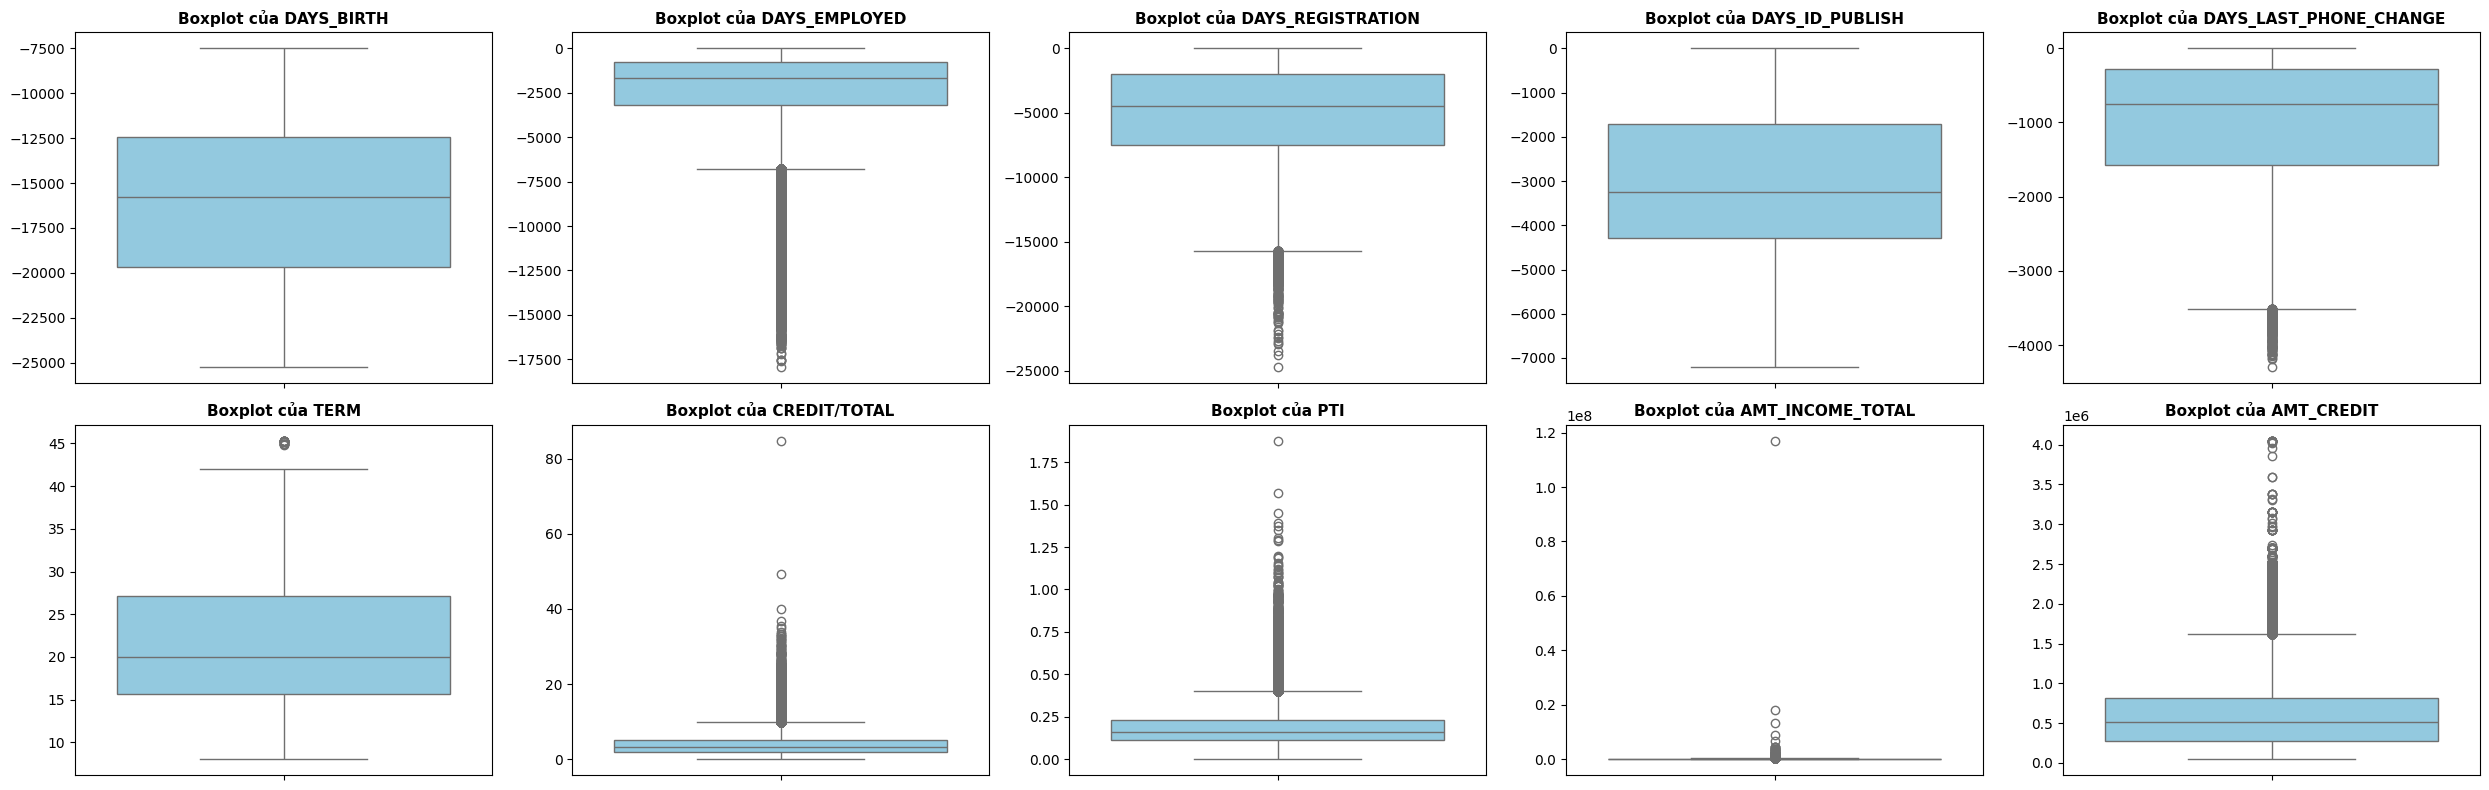

In [10]:
cols_to_plot = ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'TERM', 'CREDIT/TOTAL', 'PTI', 'AMT_INCOME_TOTAL', 'AMT_CREDIT']

n_cols = 5
n_rows = (len(cols_to_plot) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))

# Ép axes về dạng mảng 1 chiều để loop không bị lỗi
if len(cols_to_plot) == 1:
    axes = np.array([axes])
else:
    axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    # 1. Vẽ Boxplot
    sns.boxplot(data=application_train, y=col, ax=axes[i], color='skyblue', showfliers=True)
    axes[i].set_title(f'Boxplot của {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('')

    # 2. Tính toán số lượng Outlier bằng phương pháp IQR
    data_col = application_train[col].dropna() # Loại bỏ giá trị null để tính toán chính xác
    total_count = len(data_col)

    if total_count > 0:
        Q1 = data_col.quantile(0.25)
        Q3 = data_col.quantile(0.75)
        IQR = Q3 - Q1

        # Xác định ranh giới outlier
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Đếm số lượng outlier
        outliers = data_col[(data_col < lower_bound) | (data_col > upper_bound)]
        outlier_count = len(outliers)
        outlier_percentage = (outlier_count / total_count) * 100

        # In kết quả ra console
        print(f"Cột {col:<25}: Outliers = {outlier_count:<5} / Tổng = {total_count:<6} ({outlier_percentage:.2f}%)")
    else:
        print(f"Cột {col:<25}: Không có dữ liệu (Toàn bộ là NaN)")

# Xóa các ô biểu đồ trống nếu số lượng cột không lấp đầy grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [11]:
# Kiểm tra outlier là lỗi dữ liệu hay là khách hàng thật: so sánh tỉ lệ vỡ nợ của nhóm outlier với nhóm còn lại
cols_to_check_outliers = ['DAYS_REGISTRATION', 'DAYS_LAST_PHONE_CHANGE', 'TERM', 'CREDIT/TOTAL', 'PTI', 'AMT_INCOME_TOTAL']

outlier_summary = []
for col in cols_to_check_outliers:
    data_col = application_train[col].dropna()
    Q1 = data_col.quantile(0.25)
    Q3 = data_col.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    is_outlier = (application_train[col] < lower_bound) | (application_train[col] > upper_bound)
    outlier_summary.append({
        'Trường': col,
        'Số outlier': int(is_outlier.sum()),
        'Tỉ lệ outlier (%)': round(is_outlier.mean() * 100, 2),
        'Tỉ lệ vỡ nợ nhóm outlier': round(application_train.loc[is_outlier, 'TARGET'].mean(), 4),
        'Tỉ lệ vỡ nợ nhóm còn lại': round(application_train.loc[~is_outlier, 'TARGET'].mean(), 4),
    })

print(tabulate(pd.DataFrame(outlier_summary), headers='keys', tablefmt='psql', showindex=False))

# Kết luận: GIỮ LẠI outlier
# - Đây là giá trị thật (khoản vay dài hạn, thu nhập cao...), tỉ lệ vỡ nợ của nhóm outlier khác nhóm còn lại -> mang thông tin dự báo
# - Mô hình cây chia nhánh theo ngưỡng nên không bị kéo lệch bởi giá trị cực trị như hồi quy tuyến tính
# - Khi chấm điểm khách hàng mới, không thể "xóa" hồ sơ outlier -> mô hình phải học được cả nhóm này

+------------------------+--------------+---------------------+----------------------------+----------------------------+
| Trường                 |   Số outlier |   Tỉ lệ outlier (%) |   Tỉ lệ vỡ nợ nhóm outlier |   Tỉ lệ vỡ nợ nhóm còn lại |
|------------------------+--------------+---------------------+----------------------------+----------------------------|
| DAYS_REGISTRATION      |          659 |                0.21 |                     0.041  |                     0.0808 |
| DAYS_LAST_PHONE_CHANGE |          435 |                0.14 |                     0.0437 |                     0.0808 |
| TERM                   |           17 |                0.01 |                     0.3529 |                     0.0807 |
| CREDIT/TOTAL           |        11424 |                3.72 |                     0.0669 |                     0.0813 |
| PTI                    |         7872 |                2.56 |                     0.0827 |                     0.0807 |
| AMT_INCOME_TOTAL      

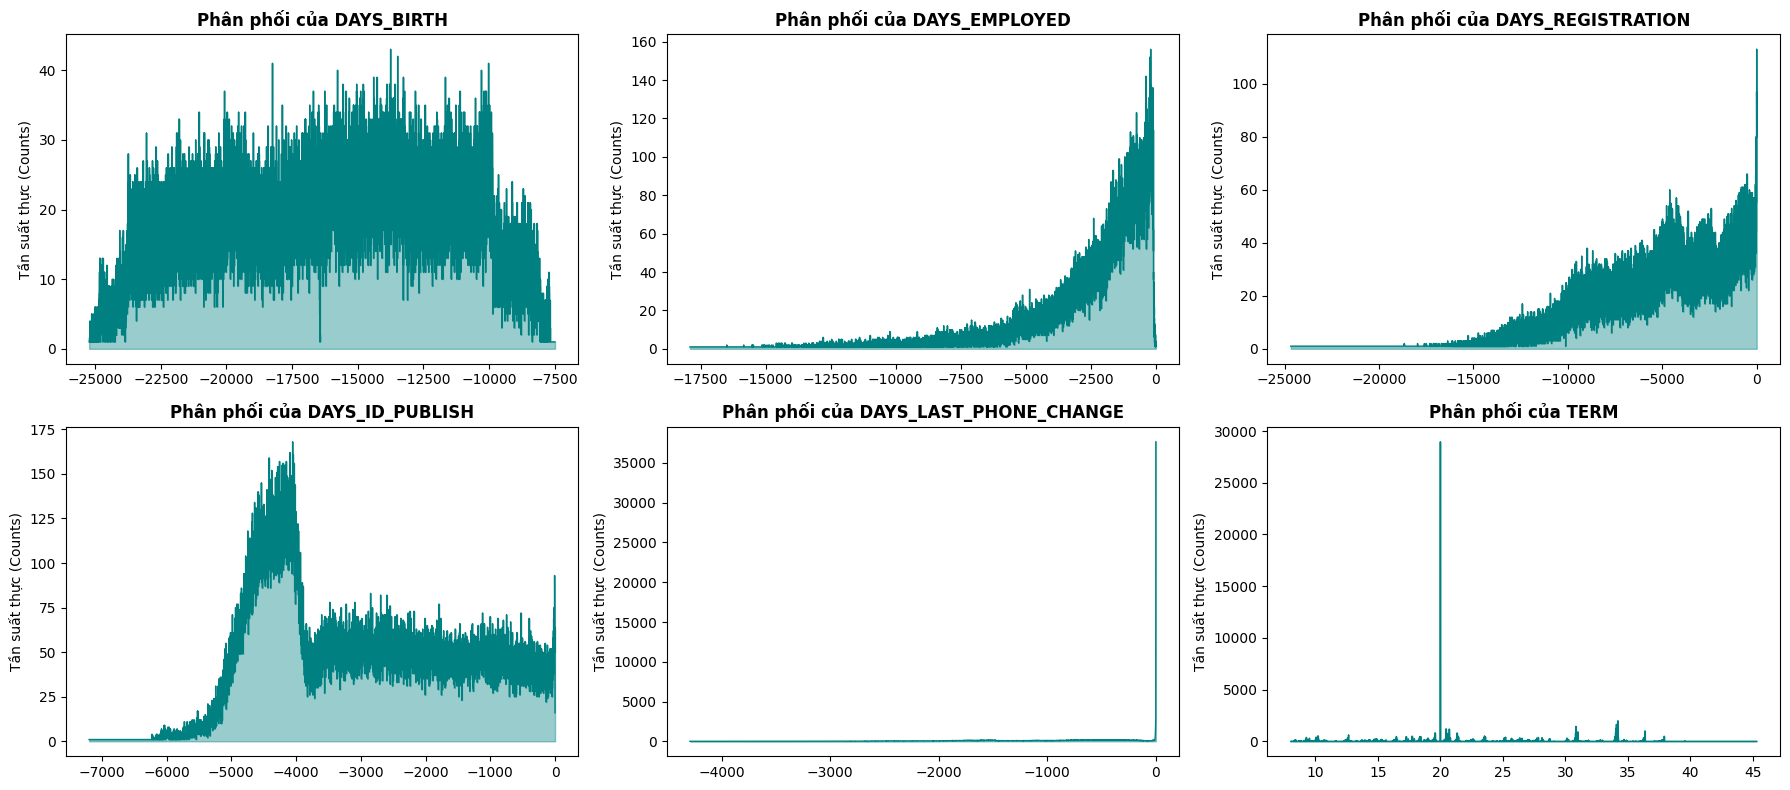

In [12]:
cols_to_plot = ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'TERM']
n_cols = 3
n_rows = (len(cols_to_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))

if len(cols_to_plot) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    # 1. Đếm chính xác tần suất độc lập từng giá trị (như value_counts)
    counts = application_train[col].value_counts().reset_index()
    counts.columns = ['value', 'count']

    # 2. Sắp xếp giá trị tăng dần theo trục X
    counts = counts.sort_values('value')

    # 3. Vẽ đường miền dựa trên TẦN SUẤT THỰC (không qua KDE hay binning)
    axes[i].plot(counts['value'], counts['count'], color='teal', linewidth=1)
    axes[i].fill_between(counts['value'], counts['count'], color='teal', alpha=0.4)

    axes[i].set_title(f'Phân phối của {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Tần suất thực (Counts)')

# Xóa các ô biểu đồ trống thừa ở cuối
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Tương quan giữa các trường

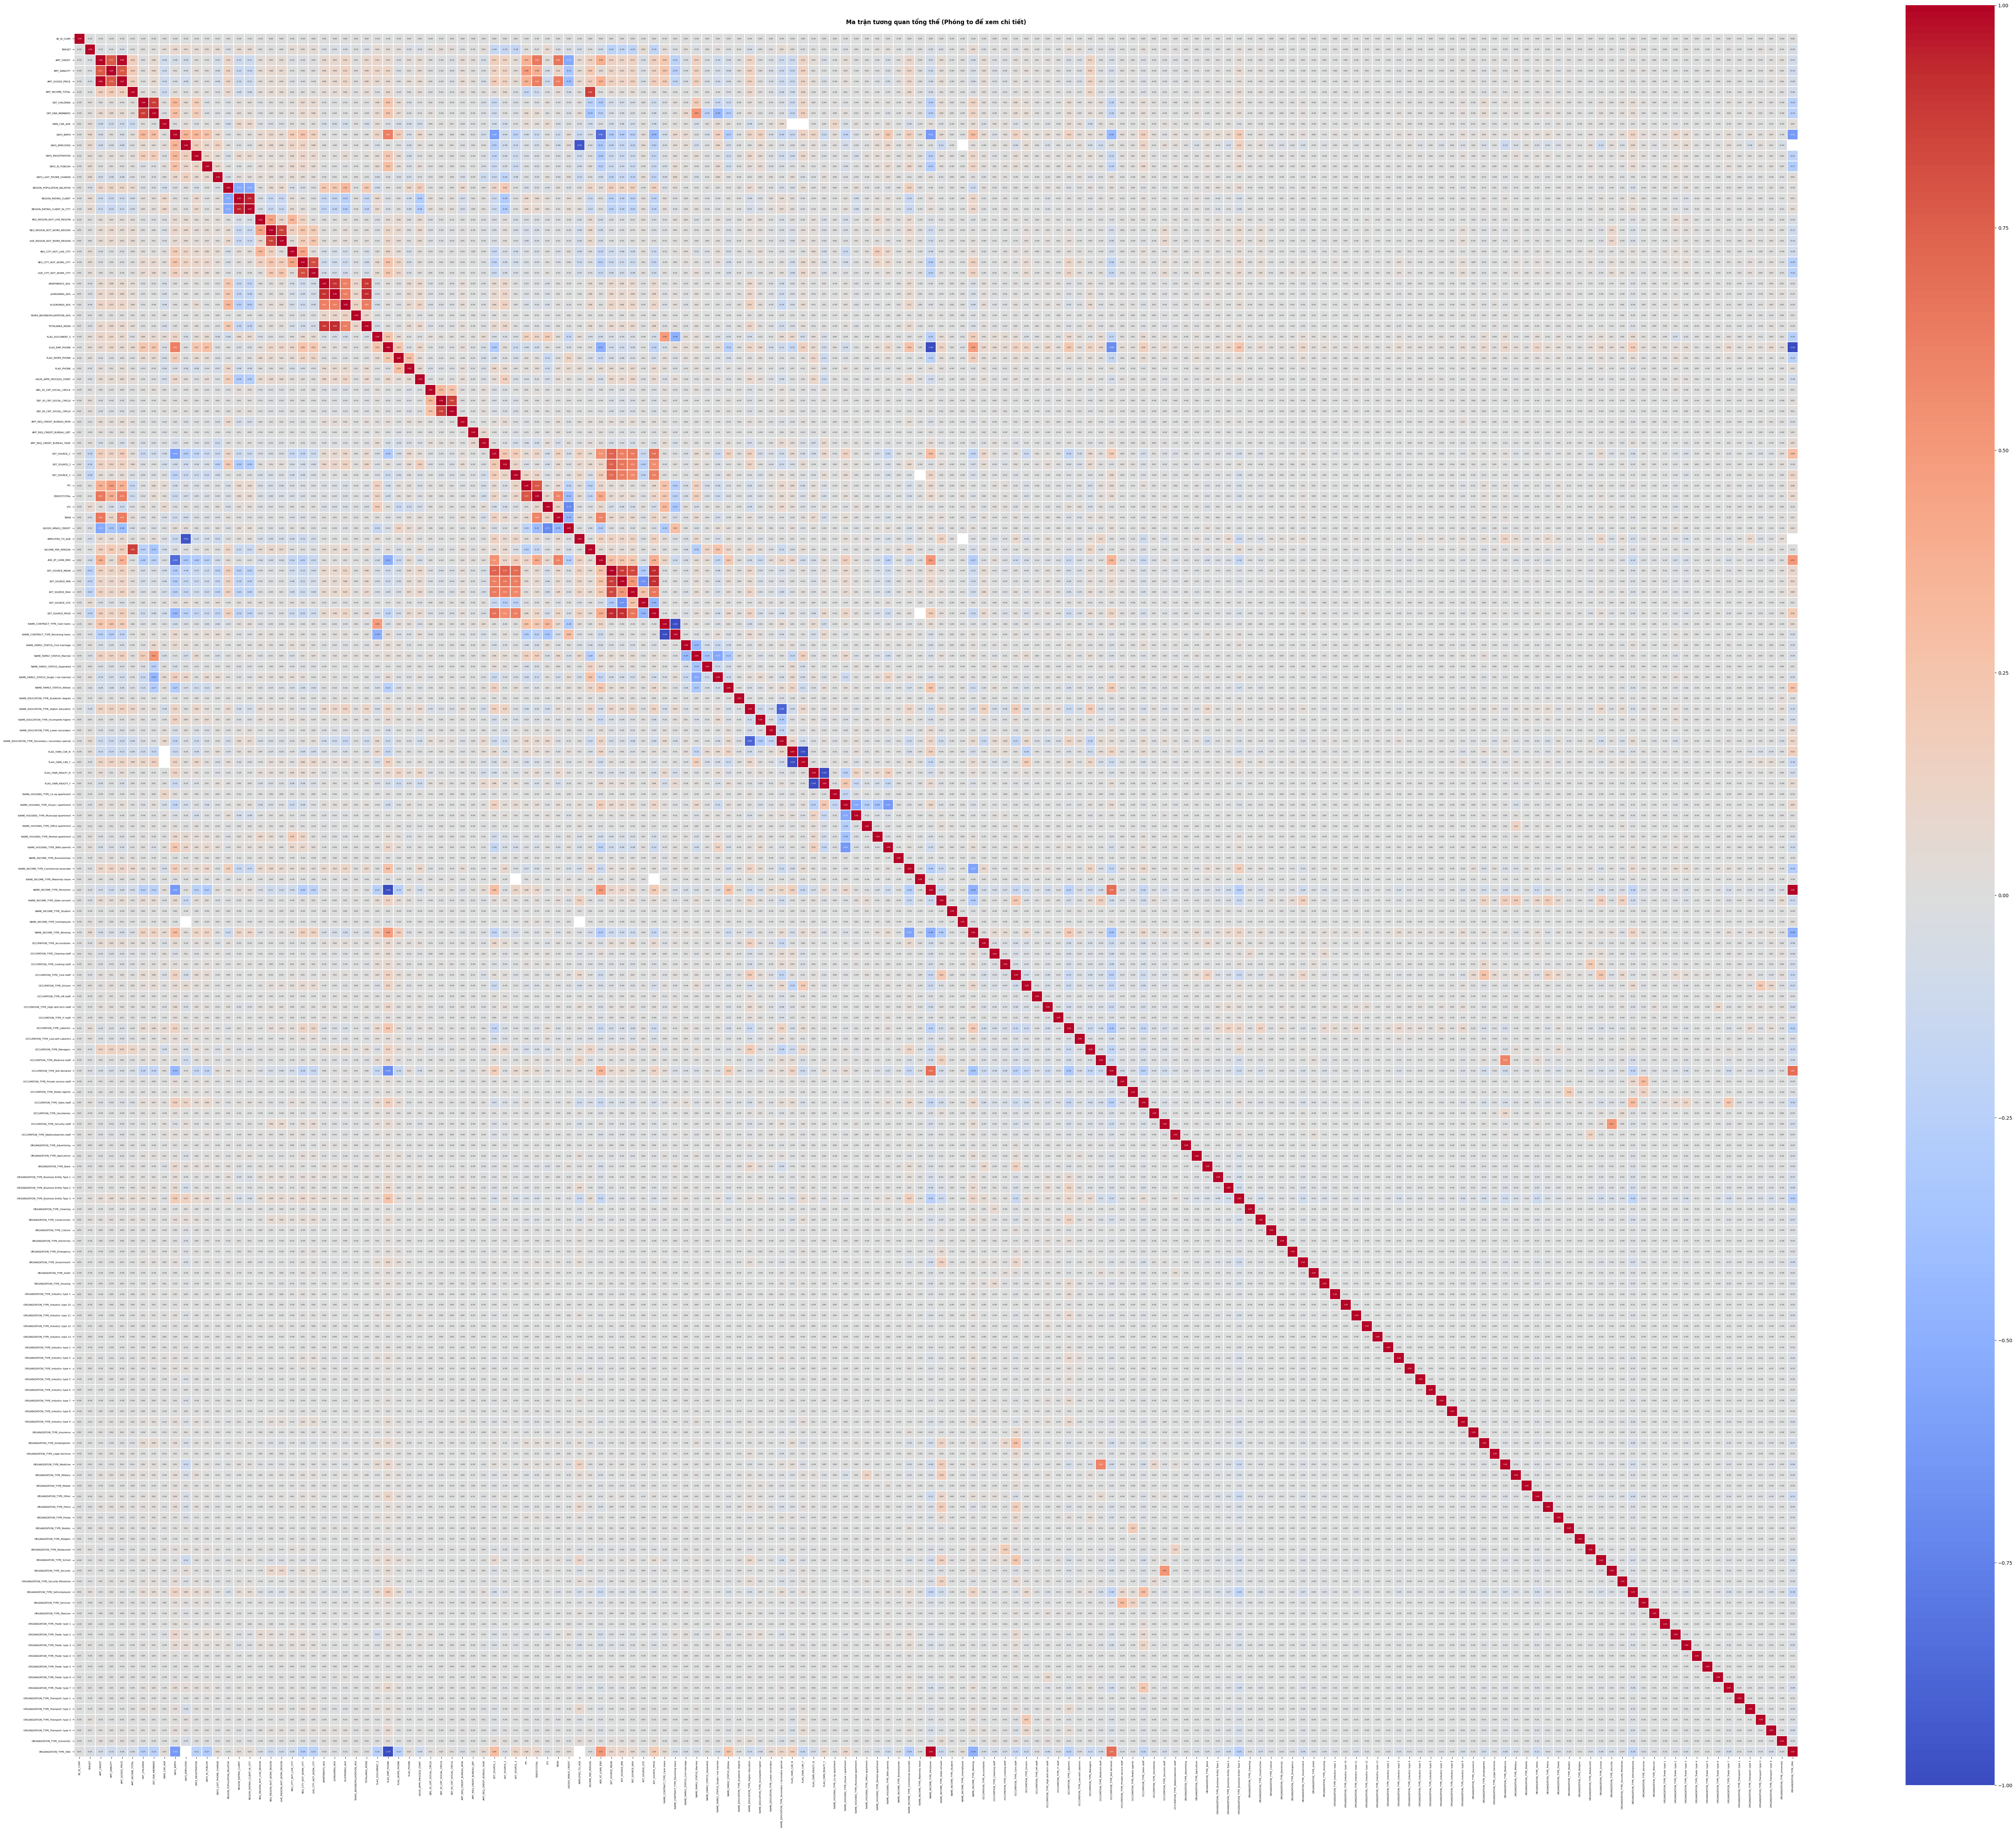

In [13]:
numeric_application = application_train.select_dtypes(include=['number'])

corr_matrix = numeric_application.corr()
num_fields = len(corr_matrix.columns)
fig_size = max(10, num_fields * 0.4)
plt.figure(figsize=(fig_size, fig_size), dpi=100)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.2,      # Đường kẻ giữa các ô mảnh lại
    cbar_kws={"shrink": 0.8}, # Thu nhỏ thanh thước đo màu
    annot_kws={"size": 4} # ĐÂY RỒI: Cho chữ số trong ô nhỏ hẳn đi (cỡ 4 hoặc 5)
)

plt.xticks(rotation=90, fontsize=5)
plt.yticks(rotation=0, fontsize=5)

plt.title('Ma trận tương quan tổng thể (Phóng to để xem chi tiết)', fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()

plt.show()

In [14]:
corr_pairs = corr_matrix.unstack()
mask = np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool)
filtered_pairs = corr_matrix.where(mask).unstack().dropna()
target_corr = corr_matrix["TARGET"]

# Lọc các cặp có giá trị tuyệt đối > 0.8
strong_pairs = filtered_pairs[abs(filtered_pairs) > 0.8]

# Sắp xếp theo mức độ tương quan giảm dần
strong_pairs_sorted = strong_pairs.reindex(
    strong_pairs.abs().sort_values(ascending=False).index
)

if not strong_pairs_sorted.empty:
    # Chuyển Series MultiIndex thành DataFrame và đặt tên cột rõ ràng
    df_strong_corr = strong_pairs_sorted.reset_index()
    df_strong_corr.columns = ["Trường 1", "Trường 2", "Hệ số tương quan (r)"]

    # Bản đồ hệ số tương quan của từng trường với TARGET
    df_strong_corr["r với TARGET (Trường 1)"] = df_strong_corr["Trường 1"].map(
        target_corr
    )
    df_strong_corr["r với TARGET (Trường 2)"] = df_strong_corr["Trường 2"].map(
        target_corr
    )

    # Định dạng hiển thị làm tròn 4 chữ số thập phân cho các cột số
    formatters = {
        "Hệ số tương quan (r)": "{:,.4f}".format,
        "r với TARGET (Trường 1)": "{:,.4f}".format,
        "r với TARGET (Trường 2)": "{:,.4f}".format,
    }
    print(df_strong_corr.to_string(index=False, formatters=formatters))
else:
    print("Không có cặp trường nào có tương quan chéo |r| > 0.8")

                            Trường 1                                          Trường 2 Hệ số tương quan (r) r với TARGET (Trường 1) r với TARGET (Trường 2)
                   FLAG_OWN_REALTY_N                                 FLAG_OWN_REALTY_Y              -1.0000                  0.0062                 -0.0062
                      FLAG_OWN_CAR_N                                    FLAG_OWN_CAR_Y              -1.0000                  0.0219                 -0.0219
       NAME_CONTRACT_TYPE_Cash loans                NAME_CONTRACT_TYPE_Revolving loans              -1.0000                  0.0310                 -0.0310
                      FLAG_EMP_PHONE                             ORGANIZATION_TYPE_XNA              -0.9999                  0.0460                 -0.0460
          NAME_INCOME_TYPE_Pensioner                             ORGANIZATION_TYPE_XNA               0.9997                 -0.0463                 -0.0460
                      FLAG_EMP_PHONE                        NAME

In [15]:
# Lọc bỏ các trường trùng lặp thông tin (|r| ≈ 1): biến bù của one-hot nhị phân, XNA trùng với nhóm hưu trí
# Các cặp 0.8 < |r| < 0.99 vẫn giữ: mô hình cây không bị ảnh hưởng bởi đa cộng tuyến
# và phần chênh lệch giữa 2 trường vẫn mang thông tin (vd: AMT_CREDIT vs AMT_GOODS_PRICE -> LTV)
application_train = application_train.drop(columns=['FLAG_OWN_REALTY_N', 'FLAG_OWN_CAR_N', 'ORGANIZATION_TYPE_XNA'])

### 2. Bureau

In [16]:
bureau = pd.read_csv("data/bureau.csv")
print(bureau.shape)
print(bureau.info())

(1716428, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1716428 entries, 0 to 1716427
Data columns (total 17 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   SK_ID_CURR              int64  
 1   SK_ID_BUREAU            int64  
 2   CREDIT_ACTIVE           object 
 3   CREDIT_CURRENCY         object 
 4   DAYS_CREDIT             int64  
 5   CREDIT_DAY_OVERDUE      int64  
 6   DAYS_CREDIT_ENDDATE     float64
 7   DAYS_ENDDATE_FACT       float64
 8   AMT_CREDIT_MAX_OVERDUE  float64
 9   CNT_CREDIT_PROLONG      int64  
 10  AMT_CREDIT_SUM          float64
 11  AMT_CREDIT_SUM_DEBT     float64
 12  AMT_CREDIT_SUM_LIMIT    float64
 13  AMT_CREDIT_SUM_OVERDUE  float64
 14  CREDIT_TYPE             object 
 15  DAYS_CREDIT_UPDATE      int64  
 16  AMT_ANNUITY             float64
dtypes: float64(8), int64(6), object(3)
memory usage: 222.6+ MB
None


In [17]:
bureau.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [18]:
# 1. Làm sạch dữ liệu bất hợp lý (giữ nguyên số dòng, chỉ chuyển giá trị sai logic thành NaN)
# Ngày kết thúc dự kiến / thực tế nằm trước ngày mở khoản vay
bureau.loc[bureau["DAYS_CREDIT_ENDDATE"] < bureau["DAYS_CREDIT"], "DAYS_CREDIT_ENDDATE"] = np.nan
bureau.loc[bureau["DAYS_ENDDATE_FACT"] < bureau["DAYS_CREDIT"], "DAYS_ENDDATE_FACT"] = np.nan
# Dư nợ âm -> 0, hạn mức thẻ <= 0 -> không xác định
bureau["AMT_CREDIT_SUM_DEBT"] = bureau["AMT_CREDIT_SUM_DEBT"].clip(lower=0)
bureau.loc[bureau["AMT_CREDIT_SUM_LIMIT"] <= 0, "AMT_CREDIT_SUM_LIMIT"] = np.nan

# 2. Không điền median / chuẩn hóa / one-hot ở cấp khoản vay:
#    bảng bureau sẽ được gom nhóm về cấp khách hàng (sum, max, mean tự bỏ qua NaN) ở mục 4,
#    điền median trước khi gom nhóm sẽ tạo ra các khoản dư nợ "ảo" cho khách hàng
print(f"Kích thước bureau: {bureau.shape}")

Kích thước bureau: (1716428, 17)


In [19]:
statistic = pd.DataFrame()
statistic["DataTypes"] = bureau.dtypes
statistic["Count_values"] = bureau.count()
statistic["Count_unique_values"] = bureau.nunique()
statistic["Count_missing_values"] = bureau.isna().sum()
statistic["Percent_missing_values"] = bureau.isna().sum() / bureau.shape[0]

pd.set_option('display.max_rows', None)
statistic

,DataTypes,Count_values,Count_unique_values,Count_missing_values,Percent_missing_values
SK_ID_CURR,int64,1716428,305811,0,0.000000
SK_ID_BUREAU,int64,1716428,1716428,0,0.000000
CREDIT_ACTIVE,object,1716428,4,0,0.000000
CREDIT_CURRENCY,object,1716428,4,0,0.000000
DAYS_CREDIT,int64,1716428,2923,0,0.000000
CREDIT_DAY_OVERDUE,int64,1716428,942,0,0.000000
DAYS_CREDIT_ENDDATE,float64,1610711,14025,105717,0.061591
DAYS_ENDDATE_FACT,float64,1082755,2914,633673,0.369181
AMT_CREDIT_MAX_OVERDUE,float64,591940,68251,1124488,0.655133
CNT_CREDIT_PROLONG,int64,1716428,10,0,0.000000


In [20]:
df_summary = bureau.select_dtypes(include=['number']).agg(['min', 'max', 'median', 'mean'])
print(tabulate(df_summary.T, headers='keys', tablefmt='psql'))

+------------------------+------------+------------------+-----------------+------------------+
|                        |        min |              max |          median |             mean |
|------------------------+------------+------------------+-----------------+------------------|
| SK_ID_CURR             | 100001     | 456255           | 278055          | 278215           |
| SK_ID_BUREAU           |      5e+06 |      6.84346e+06 |      5.9263e+06 |      5.92443e+06 |
| DAYS_CREDIT            |  -2922     |      0           |   -987          |  -1142.11        |
| CREDIT_DAY_OVERDUE     |      0     |   2792           |      0          |      0.818167    |
| DAYS_CREDIT_ENDDATE    |  -2890     |  31199           |   -330          |    514.19        |
| DAYS_ENDDATE_FACT      |  -2922     |      0           |   -897          |  -1017.39        |
| AMT_CREDIT_MAX_OVERDUE |      0     |      1.15987e+08 |      0          |   3825.42        |
| CNT_CREDIT_PROLONG     |      0     | 

Check outlier

Cột DAYS_CREDIT_UPDATE       : Outliers = 63755 / Tổng = 1716428 (3.71%)


Cột AMT_CREDIT_SUM_DEBT      : Outliers = 280326 / Tổng = 1458759 (19.22%)


Cột AMT_CREDIT_SUM           : Outliers = 187998 / Tổng = 1716415 (10.95%)


Cột DAYS_CREDIT_ENDDATE      : Outliers = 79201 / Tổng = 1610711 (4.92%)


Cột CREDIT_DAY_OVERDUE       : Outliers = 4217  / Tổng = 1716428 (0.25%)


Cột DAYS_CREDIT              : Outliers = 0     / Tổng = 1716428 (0.00%)


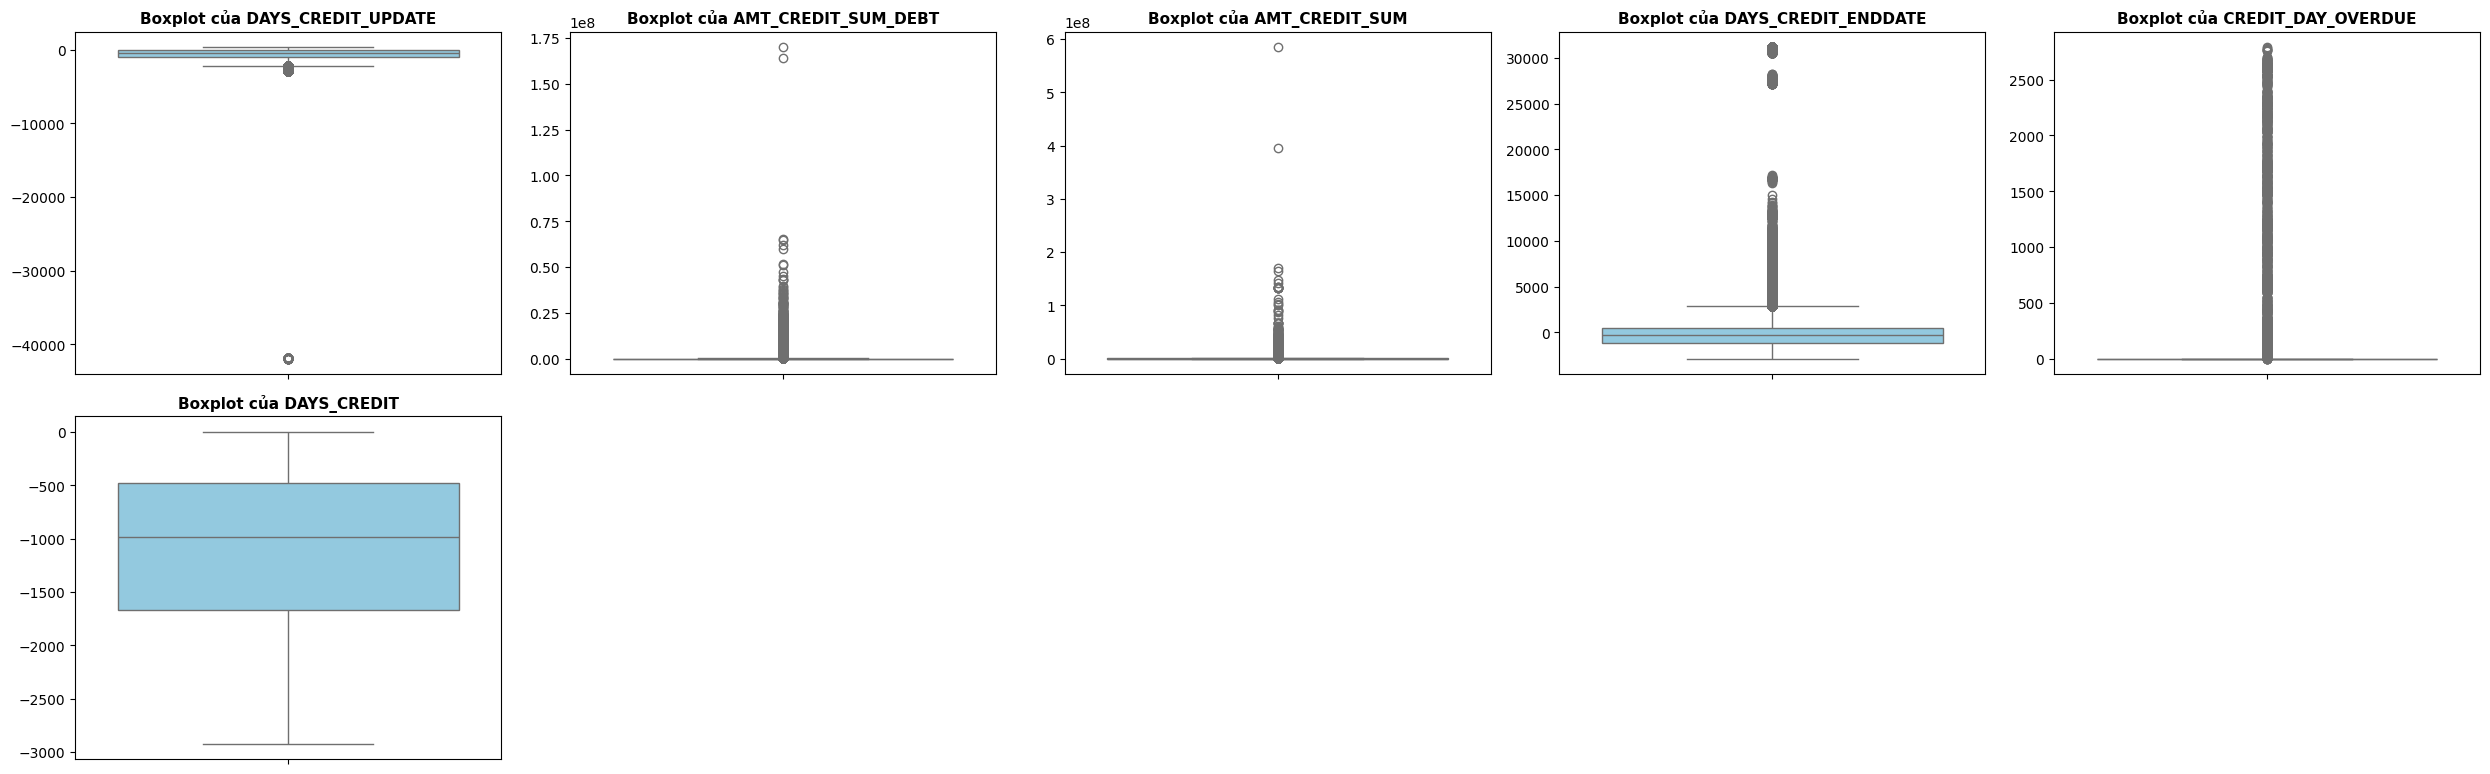

In [21]:
cols_to_plot = ['DAYS_CREDIT_UPDATE', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM', 'DAYS_CREDIT_ENDDATE', 'CREDIT_DAY_OVERDUE','DAYS_CREDIT']

n_cols = 5
n_rows = (len(cols_to_plot) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))

# Ép axes về dạng mảng 1 chiều để loop không bị lỗi
if len(cols_to_plot) == 1:
    axes = np.array([axes])
else:
    axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    # 1. Vẽ Boxplot
    sns.boxplot(data=bureau, y=col, ax=axes[i], color='skyblue', showfliers=True)
    axes[i].set_title(f'Boxplot của {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('')

    # 2. Tính toán số lượng Outlier bằng phương pháp IQR
    data_col = bureau[col].dropna() # Loại bỏ giá trị null để tính toán chính xác
    total_count = len(data_col)

    if total_count > 0:
        Q1 = data_col.quantile(0.25)
        Q3 = data_col.quantile(0.75)
        IQR = Q3 - Q1

        # Xác định ranh giới outlier
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Đếm số lượng outlier
        outliers = data_col[(data_col < lower_bound) | (data_col > upper_bound)]
        outlier_count = len(outliers)
        outlier_percentage = (outlier_count / total_count) * 100

        # In kết quả ra console
        print(f"Cột {col:<25}: Outliers = {outlier_count:<5} / Tổng = {total_count:<6} ({outlier_percentage:.2f}%)")
    else:
        print(f"Cột {col:<25}: Không có dữ liệu (Toàn bộ là NaN)")

# Xóa các ô biểu đồ trống nếu số lượng cột không lấp đầy grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [22]:
# Kiểm tra các khoản vay có AMT_CREDIT_SUM vượt ngưỡng IQR thuộc loại vay nào
data_col = bureau['AMT_CREDIT_SUM'].dropna()
Q1 = data_col.quantile(0.25)
Q3 = data_col.quantile(0.75)
upper_bound = Q3 + 1.5 * (Q3 - Q1)
is_large_credit = bureau['AMT_CREDIT_SUM'] > upper_bound

credit_type_compare = pd.DataFrame({
    'Nhóm outlier (%)': bureau.loc[is_large_credit, 'CREDIT_TYPE'].value_counts(normalize=True) * 100,
    'Toàn bộ (%)': bureau['CREDIT_TYPE'].value_counts(normalize=True) * 100,
}).round(2).sort_values('Nhóm outlier (%)', ascending=False).head(6)
print(tabulate(credit_type_compare, headers='keys', tablefmt='psql'))

# Kết luận: GIỮ LẠI toàn bộ dòng
# - Khoản vay lớn tập trung ở vay thế chấp / mua xe -> là giá trị thật, không phải lỗi nhập liệu
# - Xóa dòng ở bảng bureau = xóa một phần lịch sử tín dụng của khách hàng -> sai lệch các biến gom nhóm (số khoản vay, tổng dư nợ...)

+----------------------------------------+--------------------+---------------+
| CREDIT_TYPE                            |   Nhóm outlier (%) |   Toàn bộ (%) |
|----------------------------------------+--------------------+---------------|
| Consumer credit                        |              72.9  |         72.92 |
| Car loan                               |              12.97 |          1.61 |
| Mortgage                               |               9.66 |          1.07 |
| Credit card                            |               3.73 |         23.43 |
| Loan for business development          |               0.45 |          0.12 |
| Loan for working capital replenishment |               0.1  |          0.03 |
+----------------------------------------+--------------------+---------------+


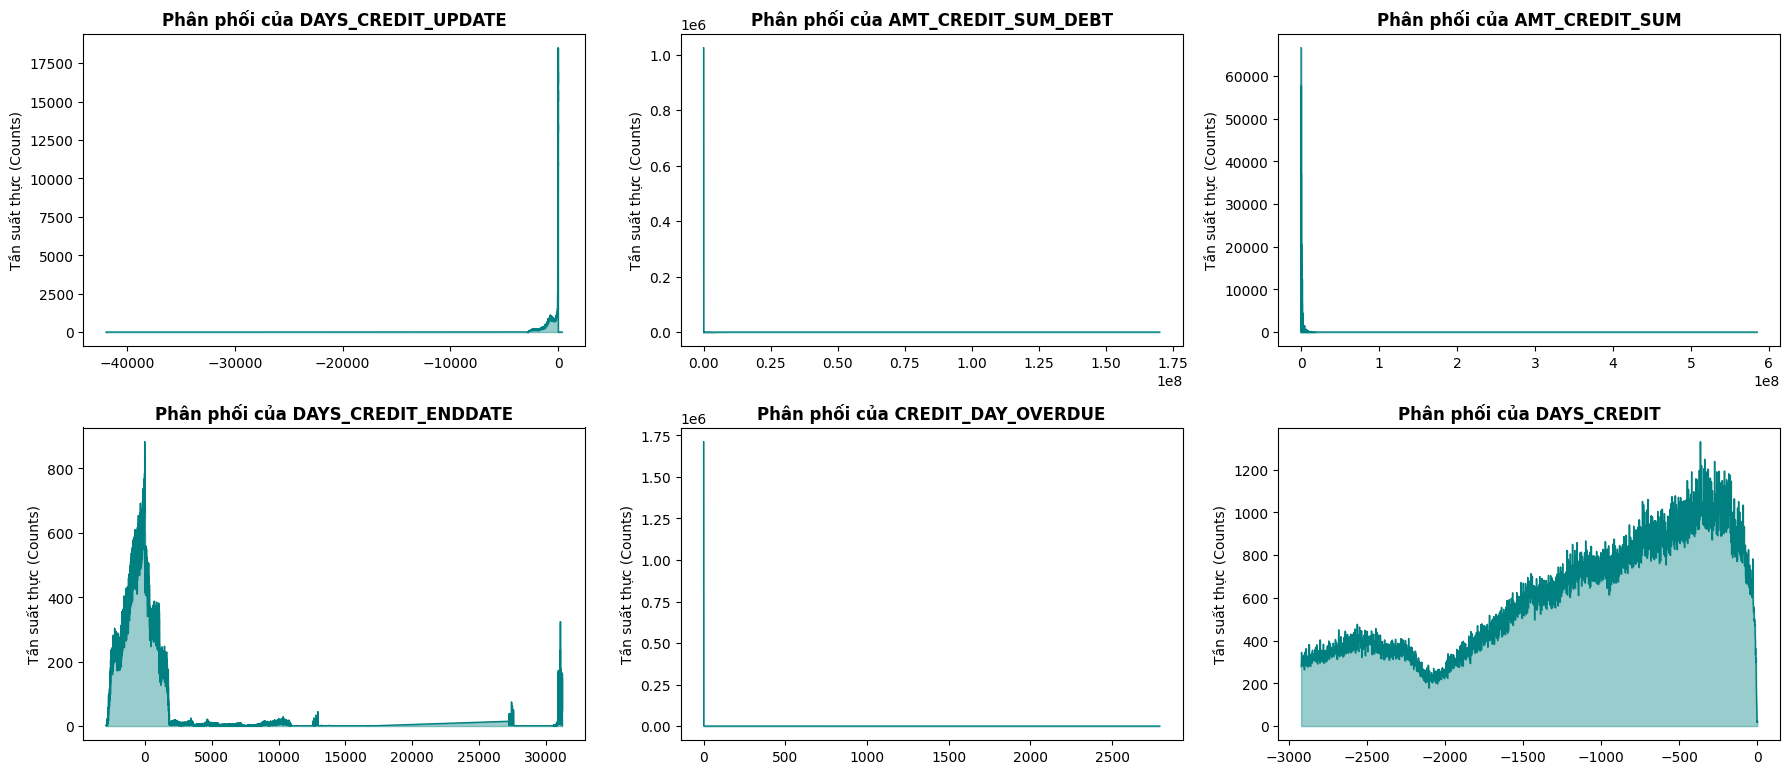

In [23]:
cols_to_plot = ['DAYS_CREDIT_UPDATE', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM', 'DAYS_CREDIT_ENDDATE', 'CREDIT_DAY_OVERDUE','DAYS_CREDIT']

n_cols = 3
n_rows = (len(cols_to_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))

if len(cols_to_plot) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    # 1. Đếm chính xác tần suất độc lập từng giá trị (như value_counts)
    counts = bureau[col].value_counts().reset_index()
    counts.columns = ['value', 'count']

    # 2. Sắp xếp giá trị tăng dần theo trục X
    counts = counts.sort_values('value')

    # 3. Vẽ đường miền dựa trên TẦN SUẤT THỰC (không qua KDE hay binning)
    axes[i].plot(counts['value'], counts['count'], color='teal', linewidth=1)
    axes[i].fill_between(counts['value'], counts['count'], color='teal', alpha=0.4)

    axes[i].set_title(f'Phân phối của {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Tần suất thực (Counts)')

# Xóa các ô biểu đồ trống thừa ở cuối
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Tương quan

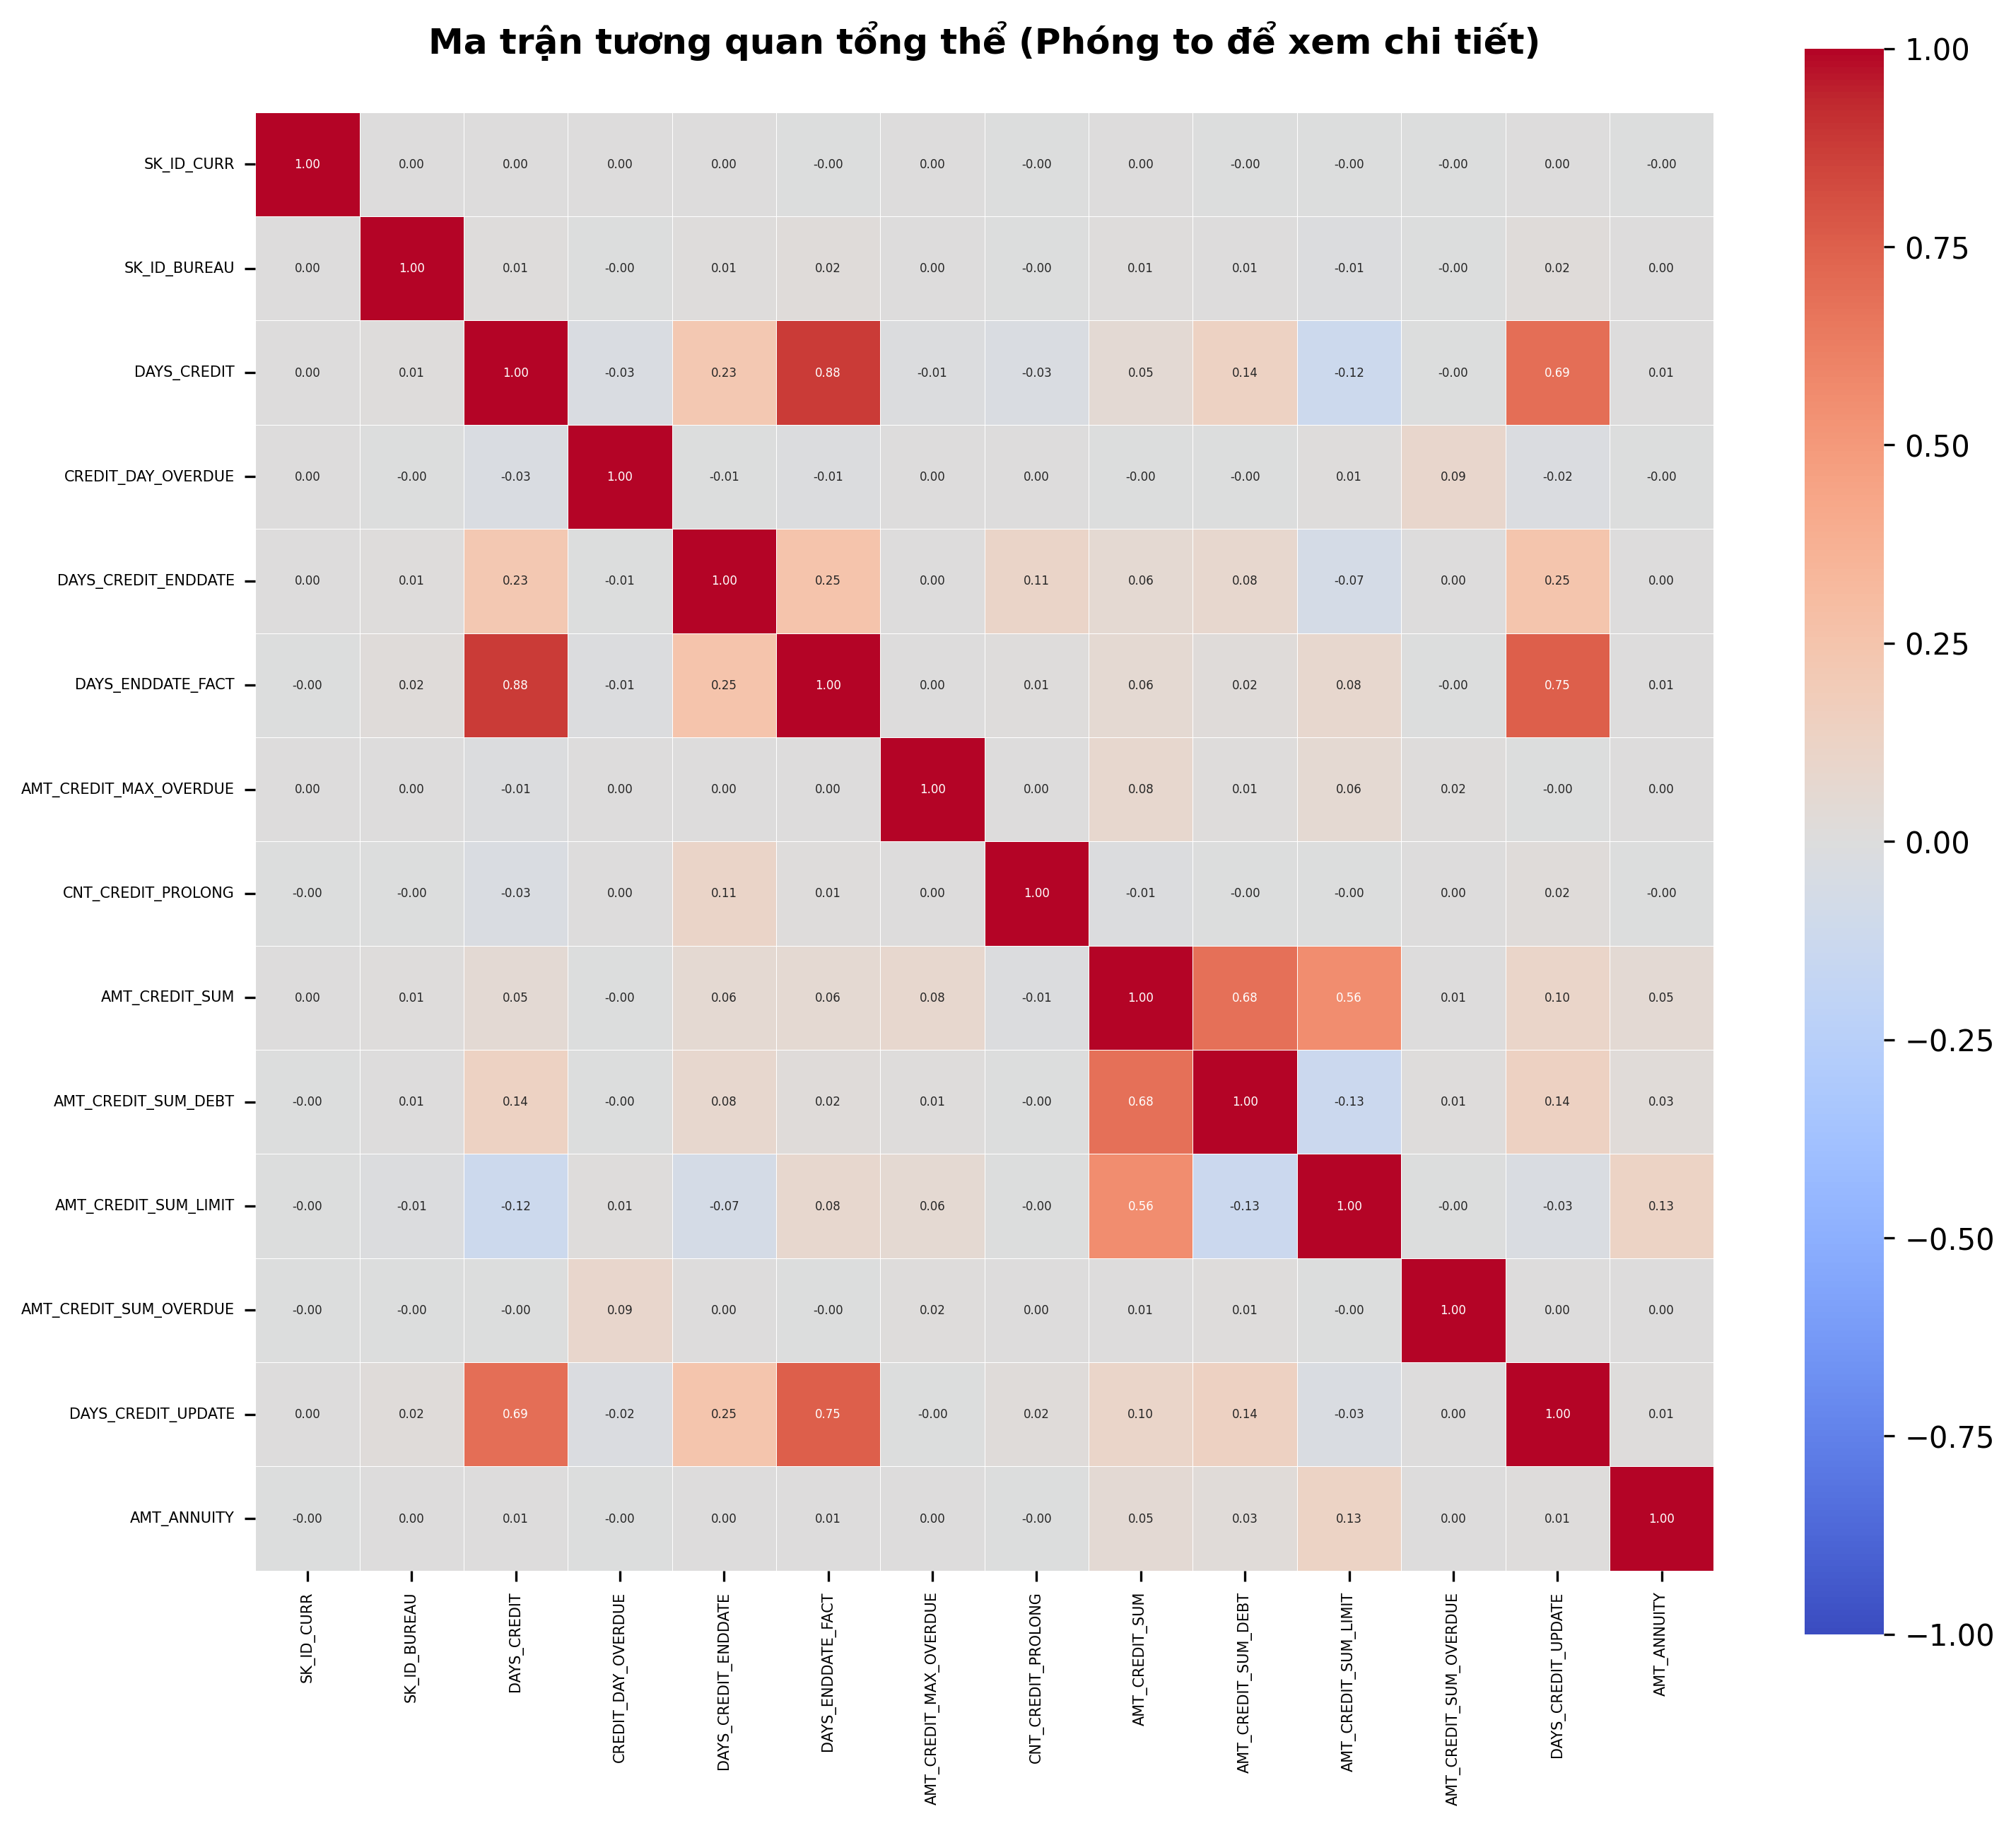

In [24]:
numeric_bureau = bureau.select_dtypes(include=['number'])

corr_matrix = numeric_bureau.corr()
num_fields = len(corr_matrix.columns)
fig_size = max(10, num_fields * 0.4)
plt.figure(figsize=(fig_size, fig_size), dpi=300)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.2,      # Đường kẻ giữa các ô mảnh lại
    cbar_kws={"shrink": 0.8}, # Thu nhỏ thanh thước đo màu
    annot_kws={"size": 4} # ĐÂY RỒI: Cho chữ số trong ô nhỏ hẳn đi (cỡ 4 hoặc 5)
)

plt.xticks(rotation=90, fontsize=5)
plt.yticks(rotation=0, fontsize=5)

plt.title('Ma trận tương quan tổng thể (Phóng to để xem chi tiết)', fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()

plt.show()

In [25]:
corr_pairs = corr_matrix.unstack()
mask = np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool)
filtered_pairs = corr_matrix.where(mask).unstack().dropna()

# Lọc các cặp có giá trị tuyệt đối > 0.8
strong_pairs = filtered_pairs[abs(filtered_pairs) > 0.8]

# Sắp xếp theo mức độ tương quan giảm dần
strong_pairs_sorted = strong_pairs.reindex(
    strong_pairs.abs().sort_values(ascending=False).index
)

if not strong_pairs_sorted.empty:
    # Chuyển Series MultiIndex thành DataFrame và đặt tên cột rõ ràng
    df_strong_corr = strong_pairs_sorted.reset_index()
    df_strong_corr.columns = ["Trường 1", "Trường 2", "Hệ số tương quan (r)"]
    # Định dạng hiển thị làm tròn 4 chữ số thập phân cho các cột số
    formatters = {
        "Hệ số tương quan (r)": "{:,.4f}".format,
        "r với TARGET (Trường 1)": "{:,.4f}".format,
        "r với TARGET (Trường 2)": "{:,.4f}".format,
    }
    print(df_strong_corr.to_string(index=False, formatters=formatters))
else:
    print("Không có cặp trường nào có tương quan chéo |r| > 0.8")

   Trường 1          Trường 2 Hệ số tương quan (r)
DAYS_CREDIT DAYS_ENDDATE_FACT               0.8767


### 3. Bureau_balance

In [26]:
# Ép kiểu dữ liệu nhỏ gọn để tiết kiệm RAM (27 triệu dòng)
bureau_balance = pd.read_csv("data/bureau_balance.csv", dtype={"SK_ID_BUREAU": "int32", "MONTHS_BALANCE": "int16", "STATUS": "category"})
print(bureau_balance.shape)
print(bureau_balance.info())

(27299925, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27299925 entries, 0 to 27299924
Data columns (total 3 columns):
 #   Column          Dtype   
---  ------          -----   
 0   SK_ID_BUREAU    int32   
 1   MONTHS_BALANCE  int16   
 2   STATUS          category
dtypes: category(1), int16(1), int32(1)
memory usage: 182.2 MB
None


In [27]:
statistic = pd.DataFrame()
statistic["DataTypes"] = bureau_balance.dtypes
statistic["Count_values"] = bureau_balance.count()
statistic["Count_unique_values"] = bureau_balance.nunique()
statistic["Count_missing_values"] = bureau_balance.isna().sum()
statistic["Percent_missing_values"] = bureau_balance.isna().sum() / bureau_balance.shape[0]

pd.set_option('display.max_rows', None)
statistic

,DataTypes,Count_values,Count_unique_values,Count_missing_values,Percent_missing_values
SK_ID_BUREAU,int32,27299925,817395,0,0.0
MONTHS_BALANCE,int16,27299925,97,0,0.0
STATUS,category,27299925,8,0,0.0


In [28]:
# BƯỚC 1: XỬ LÝ VÀ GOM NHÓM BUREAU_BALANCE (LỊCH SỬ THÁNG)
# Ép STATUS về dạng số. DPD: 0 = không quá hạn, 1..5 = nhóm quá hạn (1: 1-30 ngày ... 5: >120 ngày / bán nợ). C, X -> NaN
bureau_balance["DPD"] = pd.to_numeric(bureau_balance["STATUS"].astype(str), errors="coerce").astype("float32")
bureau_balance["IS_X"] = (bureau_balance["STATUS"] == "X").astype("int8")
bureau_balance["IS_C"] = (bureau_balance["STATUS"] == "C").astype("int8")

# Cửa sổ thời gian
in_last_12_months = bureau_balance["MONTHS_BALANCE"] >= -11
in_last_24_months = bureau_balance["MONTHS_BALANCE"] >= -23

bureau_balance["DPD_12"] = bureau_balance["DPD"].where(in_last_12_months)
bureau_balance["DPD_24"] = bureau_balance["DPD"].where(in_last_24_months)
bureau_balance["DPD1_12"] = ((bureau_balance["DPD"] >= 1) & in_last_12_months).astype("int8")
bureau_balance["DPD2_24"] = ((bureau_balance["DPD"] >= 2) & in_last_24_months).astype("int8")
bureau_balance["IS_DPD1"] = (bureau_balance["DPD"] >= 1).astype("int8")
bureau_balance["MB_DPD1"] = bureau_balance["MONTHS_BALANCE"].where(bureau_balance["DPD"] >= 1)

# 2. gộp về mỗi khoản vay một dòng
# Gom nhóm về từng khoản vay (SK_ID_BUREAU)
bureau_balance_features = (
    bureau_balance.groupby("SK_ID_BUREAU")
    .agg(
        BB_N_MONTHS=("MONTHS_BALANCE", "size"),
        BB_WORST_12M=("DPD_12", "max"),
        BB_WORST_24M=("DPD_24", "max"),
        BB_WORST_EVER=("DPD", "max"),
        BB_N_DPD1_12M=("DPD1_12", "sum"),
        BB_N_DPD2_24M=("DPD2_24", "sum"),
        BB_N_DPD1_EVER=("IS_DPD1", "sum"),
        BB_LAST_DPD=("MB_DPD1", "max"),
        BB_SHARE_X=("IS_X", "mean"),
        BB_SHARE_C=("IS_C", "mean"),
    )
    .reset_index()
)

bureau_balance_features["BB_MONTHS_SINCE_DPD"] = -bureau_balance_features.pop("BB_LAST_DPD")
bureau_balance_features["BB_EVER_DPD5"] = (bureau_balance_features["BB_WORST_EVER"] == 5).astype("int8")
bureau_balance_features["BB_SHARE_DPD1"] = bureau_balance_features["BB_N_DPD1_EVER"] / bureau_balance_features["BB_N_MONTHS"]

del bureau_balance, in_last_12_months, in_last_24_months
gc.collect()
print(f"Kích thước bureau_balance_features: {bureau_balance_features.shape}")

Kích thước bureau_balance_features: (817395, 13)


In [29]:
statistic = pd.DataFrame()
statistic["DataTypes"] = bureau_balance_features.dtypes
statistic["Count_values"] = bureau_balance_features.count()
statistic["Count_unique_values"] = bureau_balance_features.nunique()
statistic["Count_missing_values"] = bureau_balance_features.isna().sum()
statistic["Percent_missing_values"] = bureau_balance_features.isna().sum() / bureau_balance_features.shape[0]

pd.set_option('display.max_rows', None)
statistic

,DataTypes,Count_values,Count_unique_values,Count_missing_values,Percent_missing_values
SK_ID_BUREAU,int32,817395,817395,0,0.000000
BB_N_MONTHS,int64,817395,97,0,0.000000
BB_WORST_12M,float32,283202,6,534193,0.653531
BB_WORST_24M,float32,386647,6,430748,0.526977
BB_WORST_EVER,float32,687027,6,130368,0.159492
BB_N_DPD1_12M,int8,817395,13,0,0.000000
BB_N_DPD2_24M,int8,817395,25,0,0.000000
BB_N_DPD1_EVER,int8,817395,94,0,0.000000
BB_SHARE_X,float64,817395,2866,0,0.000000
BB_SHARE_C,float64,817395,2852,0,0.000000


## 4. Merge 3 file to complete dataset

In [30]:
# BƯỚC 2: MERGE LỊCH SỬ THÁNG VÀO BẢNG BUREAU (bảng bureau đã làm sạch ở mục 2, không đọc lại file CSV)
bureau = bureau.merge(bureau_balance_features, on="SK_ID_BUREAU", how="left")
bureau["HAS_BB"] = bureau["BB_N_MONTHS"].notna().astype("int8")

# Impute dữ liệu BB_* ngay cấp độ khoản vay (Avoid NaN dư thừa)
bureau["BB_MONTHS_SINCE_DPD"] = bureau["BB_MONTHS_SINCE_DPD"].fillna(9999)
bb_cols_zero = [
    "BB_N_MONTHS",
    "BB_WORST_12M",
    "BB_WORST_24M",
    "BB_WORST_EVER",
    "BB_N_DPD1_12M",
    "BB_N_DPD2_24M",
    "BB_SHARE_X",
    "BB_EVER_DPD5",
]
bureau[bb_cols_zero] = bureau[bb_cols_zero].fillna(0)

# Điều kiện lọc nghiệp vụ
is_active_loan = bureau["CREDIT_ACTIVE"].eq("Active")
is_currency_1 = bureau["CREDIT_CURRENCY"].eq("currency 1")
is_credit_card = bureau["CREDIT_TYPE"].eq("Credit card")

# Tạo các biến cờ (Flags)
bureau["IS_ACTIVE"] = is_active_loan.astype("int8")
bureau["IS_CLOSED"] = bureau["CREDIT_ACTIVE"].eq("Closed").astype("int8")
bureau["IS_BAD"] = bureau["CREDIT_ACTIVE"].isin(["Sold", "Bad debt"]).astype("int8")
bureau["NEW_6M"] = (bureau["DAYS_CREDIT"] >= -182).astype("int8")
bureau["NEW_12M"] = (bureau["DAYS_CREDIT"] >= -365).astype("int8")
bureau["ACT_PAST_END"] = (is_active_loan & (bureau["DAYS_CREDIT_ENDDATE"] < 0)).astype("int8")
has_known_end_dates = bureau["DAYS_ENDDATE_FACT"].notna() & bureau["DAYS_CREDIT_ENDDATE"].notna()
bureau["CLOSED_KNOWN"] = has_known_end_dates.astype("int8")
bureau["CLOSED_LATE"] = (has_known_end_dates & (bureau["DAYS_ENDDATE_FACT"] > bureau["DAYS_CREDIT_ENDDATE"])).astype("int8")
bureau["IS_OVERDUE_NOW"] = (bureau["CREDIT_DAY_OVERDUE"] > 0).astype("int8")
bureau["IS_PROLONG"] = (bureau["CNT_CREDIT_PROLONG"] > 0).astype("int8")
bureau["IS_MORTGAGE"] = bureau["CREDIT_TYPE"].eq("Mortgage").astype("int8")
bureau["IS_CAR"] = bureau["CREDIT_TYPE"].eq("Car loan").astype("int8")
bureau["IS_MICRO"] = bureau["CREDIT_TYPE"].eq("Microloan").astype("int8")
bureau["IS_CARD"] = is_credit_card.astype("int8")

# Số tiền có điều kiện (chỉ cộng các khoản đang hoạt động, cùng loại tiền tệ chính)
bureau["DEBT_ACT"] = bureau["AMT_CREDIT_SUM_DEBT"].where(is_active_loan & is_currency_1).fillna(0)
bureau["CREDIT_ACT"] = bureau["AMT_CREDIT_SUM"].where(is_active_loan & is_currency_1).fillna(0)
bureau["ANN_ACT"] = bureau["AMT_ANNUITY"].where(is_active_loan & is_currency_1).fillna(0)
bureau["OVD_ACT"] = bureau["AMT_CREDIT_SUM_OVERDUE"].where(is_active_loan & is_currency_1).fillna(0)

is_valid_active_card = is_active_loan & is_currency_1 & is_credit_card & bureau["AMT_CREDIT_SUM_LIMIT"].notna()
bureau["CARD_DEBT"] = bureau["AMT_CREDIT_SUM_DEBT"].where(is_valid_active_card).fillna(0)
bureau["CARD_LIMIT"] = bureau["AMT_CREDIT_SUM_LIMIT"].where(is_valid_active_card).fillna(0)
bureau["MAX_OVD_AMT"] = bureau["AMT_CREDIT_MAX_OVERDUE"].where(is_currency_1).fillna(0)

In [31]:
# BƯỚC 3: GOM NHÓM VỀ CẤP ĐỘ KHÁCH HÀNG (SK_ID_CURR)
bureau_by_customer = bureau.groupby("SK_ID_CURR")

bureau_features = bureau_by_customer.agg(
    BUR_N_LOANS=("SK_ID_BUREAU", "size"),
    BUR_N_ACTIVE=("IS_ACTIVE", "sum"),
    BUR_N_CLOSED=("IS_CLOSED", "sum"),
    BUR_EVER_BAD=("IS_BAD", "max"),
    BUR_N_NEW_6M=("NEW_6M", "sum"),
    BUR_N_NEW_12M=("NEW_12M", "sum"),
    BUR_N_ACT_PAST_END=("ACT_PAST_END", "sum"),
    BUR_N_CLOSED_KNOWN=("CLOSED_KNOWN", "sum"),
    BUR_N_CLOSED_LATE=("CLOSED_LATE", "sum"),
    BUR_N_OVERDUE_NOW=("IS_OVERDUE_NOW", "sum"),
    BUR_MAX_DPD_NOW=("CREDIT_DAY_OVERDUE", "max"),
    BUR_EVER_PROLONG=("IS_PROLONG", "max"),
    BUR_HAS_MORTGAGE=("IS_MORTGAGE", "max"),
    BUR_HAS_CAR=("IS_CAR", "max"),
    BUR_N_MICRO=("IS_MICRO", "sum"),
    BUR_N_CARD=("IS_CARD", "sum"),
    BUR_MAX_OVD_AMT=("MAX_OVD_AMT", "max"),
    _OLDEST=("DAYS_CREDIT", "min"),
    _NEWEST=("DAYS_CREDIT", "max"),
    _LAST_CLOSED=("DAYS_ENDDATE_FACT", "max"),
    BB_WORST_12M=("BB_WORST_12M", "max"),
    BB_WORST_24M=("BB_WORST_24M", "max"),
    BB_WORST_EVER=("BB_WORST_EVER", "max"),
    BB_EVER_DPD5=("BB_EVER_DPD5", "max"),
    BB_MONTHS_SINCE_DPD=("BB_MONTHS_SINCE_DPD", "min"),
    BB_SHARE_X=("BB_SHARE_X", "mean"),
    BB_N_DPD1_12M=("BB_N_DPD1_12M", "sum"),
    BB_N_DPD2_24M=("BB_N_DPD2_24M", "sum"),
    HAS_BB=("HAS_BB", "max"),
    BUR_ACTIVE_DEBT=("DEBT_ACT", "sum"),
    BUR_ACTIVE_CREDIT=("CREDIT_ACT", "sum"),
    BUR_ACTIVE_ANNUITY=("ANN_ACT", "sum"),
    BUR_ACTIVE_OVD_AMT=("OVD_ACT", "sum"),
    BUR_CARD_DEBT=("CARD_DEBT", "sum"),
    BUR_CARD_LIMIT=("CARD_LIMIT", "sum"),
)

# Chuyển đổi ngày tháng (Nếu không có ngày -> Điền 9999 đại diện cho quá khứ rất xa)
bureau_features["BUR_HIST_MONTHS"] = (-bureau_features.pop("_OLDEST") / 30.4).fillna(9999)
bureau_features["BUR_MONTHS_SINCE_NEW"] = (-bureau_features.pop("_NEWEST") / 30.4).fillna(9999)
bureau_features["BUR_MONTHS_SINCE_CLOSED"] = (-bureau_features.pop("_LAST_CLOSED") / 30.4).fillna(9999)

# Tính các tỷ lệ an toàn (Tránh chia cho 0 -> Mặc định gán 0)
def safe_div(numerator, denominator):
    result = numerator / denominator.replace(0, np.nan)
    return result.fillna(0)

bureau_features["BUR_ACTIVE_SHARE"] = safe_div(bureau_features["BUR_N_ACTIVE"], bureau_features["BUR_N_LOANS"])
bureau_features["BUR_CLOSED_LATE_RATE"] = safe_div(bureau_features["BUR_N_CLOSED_LATE"], bureau_features["BUR_N_CLOSED_KNOWN"])
bureau_features["BUR_DEBT_TO_CREDIT"] = safe_div(bureau_features["BUR_ACTIVE_DEBT"], bureau_features["BUR_ACTIVE_CREDIT"])
bureau_features["BUR_CARD_UTIL"] = safe_div(bureau_features["BUR_CARD_DEBT"], bureau_features["BUR_CARD_LIMIT"])
bureau_features["BUR_OVD_TO_DEBT"] = safe_div(bureau_features["BUR_ACTIVE_OVD_AMT"], bureau_features["BUR_ACTIVE_DEBT"])

bureau_features = bureau_features.drop(columns=["BUR_N_CLOSED_KNOWN"])

# Thống kê số học bổ sung (mean / max) cho toàn bộ khoản vay, khoản đang hoạt động và khoản đã đóng
# Các trường này GIỮ NaN khi khách hàng không có CIC (giá trị 0 sẽ mang nghĩa sai, vd: "khoản vay mở ngay hôm nay")
bureau_numeric_stats = bureau_by_customer.agg(
    BUR_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
    BUR_DAYS_CREDIT_ENDDATE_MEAN=("DAYS_CREDIT_ENDDATE", "mean"),
    BUR_DAYS_CREDIT_ENDDATE_MAX=("DAYS_CREDIT_ENDDATE", "max"),
    BUR_DAYS_CREDIT_UPDATE_MEAN=("DAYS_CREDIT_UPDATE", "mean"),
    BUR_DAYS_ENDDATE_FACT_MEAN=("DAYS_ENDDATE_FACT", "mean"),
    BUR_AMT_CREDIT_SUM_MEAN=("AMT_CREDIT_SUM", "mean"),
    BUR_AMT_CREDIT_SUM_MAX=("AMT_CREDIT_SUM", "max"),
    BUR_AMT_CREDIT_SUM_TOTAL=("AMT_CREDIT_SUM", "sum"),
    BUR_AMT_DEBT_MEAN=("AMT_CREDIT_SUM_DEBT", "mean"),
    BUR_AMT_DEBT_MAX=("AMT_CREDIT_SUM_DEBT", "max"),
    BUR_AMT_MAX_OVERDUE_MEAN=("AMT_CREDIT_MAX_OVERDUE", "mean"),
    BUR_CNT_PROLONG_SUM=("CNT_CREDIT_PROLONG", "sum"),
    BUR_BB_N_MONTHS_MEAN=("BB_N_MONTHS", "mean"),
    BUR_BB_SHARE_C_MEAN=("BB_SHARE_C", "mean"),
    BUR_BB_SHARE_DPD1_MEAN=("BB_SHARE_DPD1", "mean"),
)
bureau_active_stats = bureau[bureau["IS_ACTIVE"] == 1].groupby("SK_ID_CURR").agg(
    BUR_ACT_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
    BUR_ACT_DAYS_CREDIT_ENDDATE_MEAN=("DAYS_CREDIT_ENDDATE", "mean"),
    BUR_ACT_DAYS_UPDATE_MEAN=("DAYS_CREDIT_UPDATE", "mean"),
    BUR_ACT_AMT_CREDIT_SUM_MEAN=("AMT_CREDIT_SUM", "mean"),
)
bureau_closed_stats = bureau[bureau["IS_CLOSED"] == 1].groupby("SK_ID_CURR").agg(
    BUR_CLS_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
    BUR_CLS_DAYS_CREDIT_MAX=("DAYS_CREDIT", "max"),
    BUR_CLS_DAYS_ENDDATE_FACT_MAX=("DAYS_ENDDATE_FACT", "max"),
    BUR_CLS_AMT_CREDIT_SUM_MEAN=("AMT_CREDIT_SUM", "mean"),
)
bureau_numeric_stats = bureau_numeric_stats.join(bureau_active_stats).join(bureau_closed_stats)

bureau_features = bureau_features.join(bureau_numeric_stats).reset_index()
print(f"Kích thước bureau_features: {bureau_features.shape}")

Kích thước bureau_features: (305811, 63)


In [32]:
# BƯỚC 4: MERGE VÀO TẬP APPLICATION_TRAIN VÀ IMPUTE
n_application_rows = len(application_train)
application_train = application_train.merge(bureau_features, on="SK_ID_CURR", how="left")
assert len(application_train) == n_application_rows

application_train["HAS_BUREAU"] = application_train["BUR_N_LOANS"].notna().astype("int8")
application_train["HAS_BB"] = application_train["HAS_BB"].fillna(0).astype("int8")

# Điền 0 cho các biến đếm / cờ / dư nợ khi khách hàng không có CIC (HAS_BUREAU = 0)
# Điền 9999 cho các biến "số tháng kể từ" (chưa từng xảy ra = rất lâu), giữ NaN cho các thống kê mean / max
bureau_all_cols = [col for col in application_train.columns if col.startswith(("BUR_", "BB_"))]
for col in bureau_all_cols:
    if col in bureau_numeric_stats.columns:
        continue
    if "MONTHS_SINCE" in col:
        application_train[col] = application_train[col].fillna(9999)
    else:
        application_train[col] = application_train[col].fillna(0)

# --- Biến tương tác Application x Bureau ---
income_total = application_train["AMT_INCOME_TOTAL"]
application_train["BUR_DEBT_TO_INCOME"] = safe_div(application_train["BUR_ACTIVE_DEBT"], income_total)
application_train["TOTAL_PTI"] = application_train["PTI"] + safe_div(application_train["BUR_ACTIVE_ANNUITY"], income_total)
application_train["NEW_LOAN_SHARE"] = safe_div(
    application_train["AMT_CREDIT"],
    application_train["AMT_CREDIT"] + application_train["BUR_ACTIVE_DEBT"],
)

# Tách 2 bộ Cash & Revolving (2 sản phẩm có hành vi trả nợ khác nhau -> xây mô hình riêng)
cash_mask = application_train["NAME_CONTRACT_TYPE_Cash loans"] == 1
revolving_mask = application_train["NAME_CONTRACT_TYPE_Revolving loans"] == 1

drop_split_cols = ["NAME_CONTRACT_TYPE_Cash loans", "NAME_CONTRACT_TYPE_Revolving loans", "SK_ID_CURR"]
application_train_cash = application_train[cash_mask].drop(columns=drop_split_cols).reset_index(drop=True)
application_train_revolving = application_train[revolving_mask].drop(columns=drop_split_cols).reset_index(drop=True)

# Giải phóng RAM trước khi huấn luyện
del bureau, bureau_by_customer, bureau_features, bureau_active_stats, bureau_closed_stats, bureau_balance_features, application_train
gc.collect()

print(f"Kích thước bộ Cash loans: {application_train_cash.shape}")
print(f"Kích thước bộ Revolving loans: {application_train_revolving.shape}")

Kích thước bộ Cash loans: (278220, 222)
Kích thước bộ Revolving loans: (29001, 222)


In [33]:
statistic = pd.DataFrame()
statistic["DataTypes"] = application_train_cash.dtypes
statistic["Count_values"] = application_train_cash.count()
statistic["Count_unique_values"] = application_train_cash.nunique()
statistic["Count_missing_values"] = application_train_cash.isna().sum()
statistic["Percent_missing_values"] = application_train_cash.isna().sum() / application_train_cash.shape[0]

pd.set_option('display.max_rows', None)
statistic

,DataTypes,Count_values,Count_unique_values,Count_missing_values,Percent_missing_values
TARGET,int64,278220,2,0,0.000000
AMT_CREDIT,float64,278220,5603,0,0.000000
AMT_ANNUITY,float64,278220,13656,0,0.000000
AMT_GOODS_PRICE,float64,278220,1002,0,0.000000
AMT_INCOME_TOTAL,float64,278220,2363,0,0.000000
CNT_CHILDREN,int64,278220,15,0,0.000000
CNT_FAM_MEMBERS,float64,278220,17,0,0.000000
OWN_CAR_AGE,float64,94449,62,183771,0.660524
DAYS_BIRTH,int64,278220,17293,0,0.000000
DAYS_EMPLOYED,float64,226212,12378,52008,0.186931


In [34]:
target_counts = application_train_cash['TARGET'].value_counts()
print(target_counts)
print(f"Tỉ lệ vỡ nợ: {target_counts[1] / target_counts.sum():.2%} -> lệch nhãn nặng, khoảng {target_counts[0] / target_counts[1]:.1f} hồ sơ tốt / 1 hồ sơ vỡ nợ")

TARGET
0    254999
1     23221
Name: count, dtype: int64
Tỉ lệ vỡ nợ: 8.35% -> lệch nhãn nặng, khoảng 11.0 hồ sơ tốt / 1 hồ sơ vỡ nợ


## 5. Xử lí dữ liệu lệch nhãn

In [35]:
from sklearn.model_selection import train_test_split

# 1. Tách đặc trưng và nhãn
X = application_train_cash.drop(columns=["TARGET"])
y = application_train_cash["TARGET"]

# Thay thế các ký tự đặc biệt JSON như [, ], {, }, ", :, , thành dấu gạch dưới '_' (XGBoost / LightGBM không chấp nhận)
X.columns = [re.sub(r'[\[\]\{\}\":,]', '_', col) for col in X.columns]

# 2. Tách tập kiểm tra hold-out 20% TRƯỚC mọi bước xử lí lệch nhãn / tinh chỉnh tham số
#    -> tập test giữ nguyên phân phối thật (~8% vỡ nợ), chỉ dùng 1 lần để đánh giá cuối cùng
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()

print(f"=> Kích thước X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"=> Tỉ lệ vỡ nợ train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")
print(f"=> Tỉ lệ lệch nhãn (Không vỡ nợ / Vỡ nợ): {imbalance_ratio:.2f} : 1")

=> Kích thước X_train: (222576, 221) | X_test: (55644, 221)
=> Tỉ lệ vỡ nợ train: 0.0835 | test: 0.0835
=> Tỉ lệ lệch nhãn (Không vỡ nợ / Vỡ nợ): 10.98 : 1


So sánh các chiến lược xử lí lệch nhãn (5-fold CV trên tập train, LightGBM cấu hình cố định):
1. **Không xử lí**: học trên phân phối gốc
2. **Class weight**: tăng trọng số lỗi của lớp vỡ nợ theo tỉ lệ lệch nhãn (không tạo thêm / bỏ bớt dữ liệu)
3. **SMOTE**: sinh mẫu vỡ nợ tổng hợp bằng nội suy k láng giềng gần nhất
4. **Random Undersampling**: bỏ bớt ngẫu nhiên hồ sơ không vỡ nợ cho cân bằng 1 : 1

SMOTE / Undersampling được đặt **bên trong Pipeline** -> chỉ áp dụng lên các fold huấn luyện, fold kiểm định vẫn giữ phân phối thật.
Nếu SMOTE trước khi chia fold/train-test, mẫu tổng hợp được nội suy từ chính các điểm sẽ nằm trong tập kiểm định -> kết quả đánh giá bị "ảo".

In [36]:
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate
from lightgbm import LGBMClassifier

base_lgbm_params = dict(
    n_estimators=400, learning_rate=0.05, num_leaves=31, colsample_bytree=0.4,
    subsample=0.85, subsample_freq=1, min_child_samples=100,
    deterministic=True, force_row_wise=True, verbose=-1, n_jobs=-1, random_state=42
)

imbalance_strategies = {
    '1. Không xử lí': LGBMClassifier(**base_lgbm_params),
    '2. Class weight': LGBMClassifier(**base_lgbm_params, scale_pos_weight=imbalance_ratio),
    # SMOTE không nhận NaN -> điền median trước (fit trong từng fold)
    '3. SMOTE': ImbalancedPipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('smote', SMOTE(random_state=42)),
        ('model', LGBMClassifier(**base_lgbm_params)),
    ]),
    '4. Random Undersampling': ImbalancedPipeline([
        ('undersampler', RandomUnderSampler(random_state=42)),
        ('model', LGBMClassifier(**base_lgbm_params)),
    ]),
}

strategy_scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}
strategy_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

strategy_results = []
for strategy_name, strategy_model in imbalance_strategies.items():
    cv_scores = cross_validate(strategy_model, X_train, y_train, cv=strategy_cv, scoring=strategy_scoring, n_jobs=1)
    strategy_results.append({
        'Chiến lược': strategy_name,
        'ROC-AUC': cv_scores['test_roc_auc'].mean(),
        'PR-AUC': cv_scores['test_pr_auc'].mean(),
        'Precision@0.5': cv_scores['test_precision'].mean(),
        'Recall@0.5': cv_scores['test_recall'].mean(),
        'F1@0.5': cv_scores['test_f1'].mean(),
    })
    print(f"Xong: {strategy_name}")

strategy_results = pd.DataFrame(strategy_results)
print(tabulate(strategy_results, headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

Xong: 1. Không xử lí


Xong: 2. Class weight


Xong: 3. SMOTE


Xong: 4. Random Undersampling
+-------------------------+-----------+----------+-----------------+--------------+----------+
| Chiến lược              |   ROC-AUC |   PR-AUC |   Precision@0.5 |   Recall@0.5 |   F1@0.5 |
|-------------------------+-----------+----------+-----------------+--------------+----------|
| 1. Không xử lí          |    0.7712 |   0.2673 |          0.5602 |       0.0354 |   0.0665 |
| 2. Class weight         |    0.7702 |   0.2671 |          0.1883 |       0.6553 |   0.2925 |
| 3. SMOTE                |    0.7703 |   0.2643 |          0.5721 |       0.0332 |   0.0627 |
| 4. Random Undersampling |    0.7670 |   0.2584 |          0.1745 |       0.6929 |   0.2788 |
+-------------------------+-----------+----------+-----------------+--------------+----------+


Kết luận so sánh chiến lược lệch nhãn:
- **ROC-AUC / PR-AUC gần như không đổi** giữa các chiến lược (~0.77): xử lí lệch nhãn **không** làm mô hình xếp hạng khách hàng tốt hơn, chỉ làm dịch chuyển xác suất dự đoán.
- Khác biệt nằm ở **ngưỡng quyết định 0.5**: không xử lí / SMOTE gần như không bắt được ca vỡ nợ (Recall ~0.03), Class weight đưa Recall lên ~0.65.
- SMOTE tốn thêm thời gian, sinh dữ liệu giả (biến one-hot thành giá trị lẻ 0.3, 0.7...) mà không cải thiện AUC; Undersampling bỏ ~90% dữ liệu tốt nên AUC giảm.

=> Chọn **Class weight** (`scale_pos_weight` / `class_weight`) + **chọn ngưỡng quyết định tối ưu F1 trên dự đoán OOF** của tập train, áp dụng cho cả 3 mô hình RF, XGBoost, LightGBM.

## 6. Trainning model

In [37]:
import os
import json
import copy
import onnxruntime as ort

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, ParameterGrid, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report
)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from skl2onnx import convert_sklearn
import skl2onnx.common.data_types as skl_types

import onnxmltools.convert.common.data_types as onnx_types
from onnxmltools.convert import convert_xgboost, convert_lightgbm


def find_best_f1_threshold(y_true, probabilities):
    """Tìm ngưỡng xác suất cho F1 của lớp vỡ nợ cao nhất"""
    precisions, recalls, thresholds = precision_recall_curve(y_true, probabilities)
    f1_scores = 2 * precisions[:-1] * recalls[:-1] / np.clip(precisions[:-1] + recalls[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1_scores)])


def evaluate_predictions(y_true, probabilities, threshold):
    """Tính toàn bộ chỉ số đánh giá tại một ngưỡng xác suất"""
    predictions = (probabilities >= threshold).astype(int)
    false_positive_rates, true_positive_rates, _ = roc_curve(y_true, probabilities)
    roc_auc = roc_auc_score(y_true, probabilities)
    return {
        'threshold': float(threshold),
        'accuracy': float(accuracy_score(y_true, predictions)),
        'precision': float(precision_score(y_true, predictions)),
        'recall': float(recall_score(y_true, predictions)),
        'f1': float(f1_score(y_true, predictions)),
        'roc_auc': float(roc_auc),
        'pr_auc': float(average_precision_score(y_true, probabilities)),
        'gini': float(2 * roc_auc - 1),
        'ks': float(np.max(true_positive_rates - false_positive_rates)),
    }


def predict_onnx_probabilities(onnx_path, features):
    """Chạy model ONNX và lấy xác suất của lớp vỡ nợ"""
    session = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    outputs = session.run(None, {session.get_inputs()[0].name: features})
    probabilities = outputs[1]
    if isinstance(probabilities, list):
        probabilities = np.array([row[1] for row in probabilities])
    return np.asarray(probabilities)[:, 1]

In [38]:
# 1. Tạo thư mục lưu artifacts
artifact_dir = "mlops_artifacts"
os.makedirs(artifact_dir, exist_ok=True)

# 2. Định nghĩa danh sách mô hình và không gian tham số
#    Xử lí lệch nhãn: Class weight (theo kết quả so sánh ở mục 5) + chọn ngưỡng quyết định tối ưu F1 trên OOF
models_and_params = {
    'RandomForest': {
        # RandomForest: điền giá trị thiếu bằng hằng số rất nhỏ -> cây vẫn tách được nhóm "thiếu" thành nhánh riêng
        'model': Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value=-999999)),
            ('model', RandomForestClassifier(
                n_estimators=300,
                max_features='sqrt',
                class_weight='balanced_subsample',
                n_jobs=-1,
                random_state=42
            )),
        ]),
        'params': {
            'model__max_depth': [24, 32],               # Giới hạn độ sâu để tránh học vẹt
            'model__min_samples_leaf': [10, 20]         # Lá đủ lớn giúp xác suất ổn định hơn với lớp thiểu số
        }
    },
    'XGBoost': {
        'model': XGBClassifier(
            n_estimators=2000,                         # Số cây chọn bằng early stopping trên CV tập train (lr = 0.02)
            learning_rate=0.02,
            subsample=0.85,
            colsample_bytree=0.3,
            tree_method='hist',                        # Dùng thuật toán 'hist' tối ưu tốc độ cho dataset lớn
            eval_metric='auc',
            scale_pos_weight=imbalance_ratio,
            n_jobs=-1,
            random_state=42
        ),
        'params': {
            'max_depth': [3, 4],
            'min_child_weight': [50, 150]
        }
    },
    'LightGBM': {
        'model': LGBMClassifier(
            n_estimators=1400,                         # Số cây chọn bằng early stopping trên CV tập train (lr = 0.02)
            learning_rate=0.02,
            subsample=0.85,
            subsample_freq=1,
            colsample_bytree=0.2,
            reg_lambda=1.0,
            scale_pos_weight=imbalance_ratio,
            deterministic=True,                        # Cố định kết quả khi chạy lại
            force_row_wise=True,
            verbose=-1,
            n_jobs=-1,
            random_state=42
        ),
        'params': {
            'num_leaves': [16, 24],                    # LightGBM dùng num_leaves thay cho max_depth
            'min_child_samples': [200, 400]
        }
    }
}

# 3. Khởi tạo Stratified K-Fold cho tinh chỉnh tham số + dự đoán OOF (chỉ trên tập train)
tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
n_features = X_train.shape[1]
feature_names = X_train.columns.tolist()
X_test_float = X_test.to_numpy(dtype=np.float32)

# Phân tách FloatTensorType riêng cho skl2onnx và onnxmltools
initial_type_skl = [('float_input', skl_types.FloatTensorType([None, n_features]))]
initial_type_onnx = [('float_input', onnx_types.FloatTensorType([None, n_features]))]

results = {}

# 4. Huấn luyện, Đánh giá & Export MLOps Artifacts
for model_name, config in models_and_params.items():
    print(f"\n===>TỐI ƯU HÓA & HUẤN LUYỆN: {model_name.upper()}")
    num_combinations = len(ParameterGrid(config['params']))
    print(f"  Số tổ hợp tham số: {num_combinations} x {tuning_cv.get_n_splits()} folds = {num_combinations * tuning_cv.get_n_splits()} lần fit")

    # 4.1. GridSearch trên tập train (chạy tuần tự từng fit, mỗi model tự dùng toàn bộ CPU -> tránh nhân bản dữ liệu gây tràn RAM)
    grid_search = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=tuning_cv,
        scoring='roc_auc',
        n_jobs=1,
        verbose=1
    )
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

    # 4.2. Dự đoán Out-Of-Fold (OOF) trên tập train với tham số tốt nhất -> chọn ngưỡng quyết định
    oof_probabilities = cross_val_predict(
        clone(best_model), X_train, y_train, cv=tuning_cv, method='predict_proba', n_jobs=1
    )[:, 1]
    best_threshold = find_best_f1_threshold(y_train, oof_probabilities)
    metrics_oof = evaluate_predictions(y_train, oof_probabilities, best_threshold)

    # 4.3. Đánh giá trên tập test hold-out (phân phối thật, chưa từng dùng khi huấn luyện / tinh chỉnh)
    test_probabilities = best_model.predict_proba(X_test)[:, 1]
    metrics_test = evaluate_predictions(y_test, test_probabilities, best_threshold)
    metrics_test_default = evaluate_predictions(y_test, test_probabilities, 0.5)
    test_predictions = (test_probabilities >= best_threshold).astype(int)
    cm = confusion_matrix(y_test, test_predictions)
    cls_report = classification_report(y_test, test_predictions, digits=4)

    # 4.4. MLOPS EXPORT LOGIC
    model_folder = os.path.join(artifact_dir, model_name)
    os.makedirs(model_folder, exist_ok=True)
    onnx_path = os.path.join(model_folder, "model.onnx")

    if model_name == 'RandomForest':
        onnx_model = convert_sklearn(best_model, initial_types=initial_type_skl, options={RandomForestClassifier: {'zipmap': False}})

    elif model_name == 'XGBoost':
        best_model.save_model(os.path.join(model_folder, "model.json"))
        # Đổi feature_names trên bản sao trước khi convert (giữ nguyên tên cột cho model gốc)
        onnx_ready_model = copy.deepcopy(best_model)
        onnx_ready_model.get_booster().feature_names = [f"f{i}" for i in range(n_features)]
        onnx_model = convert_xgboost(onnx_ready_model, initial_types=initial_type_onnx)

    elif model_name == 'LightGBM':
        best_model.booster_.save_model(os.path.join(model_folder, "model.txt"))
        onnx_model = convert_lightgbm(best_model, initial_types=initial_type_onnx, zipmap=False)

    with open(onnx_path, "wb") as f:
        f.write(onnx_model.SerializeToString())

    # Kiểm tra model ONNX cho kết quả giống model gốc (ONNX tính bằng float32 -> lệch rất nhỏ ở các điểm sát ngưỡng chia)
    onnx_probabilities = predict_onnx_probabilities(onnx_path, X_test_float)
    onnx_mean_difference = float(np.mean(np.abs(onnx_probabilities - test_probabilities)))
    onnx_roc_auc = float(roc_auc_score(y_test, onnx_probabilities))

    # Xuất Metadata
    metadata = {
        'model_name': model_name,
        'best_params': grid_search.best_params_,
        'decision_threshold': best_threshold,
        'metrics_oof': metrics_oof,
        'metrics_test': metrics_test,
        'onnx_mean_abs_difference': onnx_mean_difference,
        'onnx_roc_auc_test': onnx_roc_auc,
        'input_shape': [-1, n_features],
        'feature_names': feature_names
    }
    with open(os.path.join(model_folder, "metadata.json"), "w") as f:
        json.dump(metadata, f, indent=4, ensure_ascii=False)

    results[model_name] = {
        'model': best_model,
        'best_params': grid_search.best_params_,
        'threshold': best_threshold,
        'metrics_oof': metrics_oof,
        'metrics_test': metrics_test,
        'metrics_test_default': metrics_test_default,
        'oof_probabilities': oof_probabilities,
        'test_probabilities': test_probabilities,
        'confusion_matrix': cm,
        'report': cls_report,
        'artifact_path': model_folder
    }

    print(f"\n [LOG HOÀN THÀNH] MÔ HÌNH: {model_name.upper()}")
    print(f"  • Siêu tham số tốt nhất : {grid_search.best_params_}")
    print(f"  • ROC-AUC CV (tuning)   : {grid_search.best_score_:.4f}")
    print(f"  • Ngưỡng quyết định     : {best_threshold:.4f} (tối ưu F1 trên OOF)")
    print(f"  • Accuracy              : {metrics_test['accuracy']:.4f}")
    print(f"  • Precision             : {metrics_test['precision']:.4f}")
    print(f"  • Recall                : {metrics_test['recall']:.4f}")
    print(f"  • F1-Score              : {metrics_test['f1']:.4f}")
    print(f"  • ROC-AUC (Test)        : {metrics_test['roc_auc']:.4f}")
    print(f"  • PR-AUC (Test)         : {metrics_test['pr_auc']:.4f}")
    print(f"  • Gini / KS (Test)      : {metrics_test['gini']:.4f} / {metrics_test['ks']:.4f}")
    print(f"  • ONNX sai lệch TB      : {onnx_mean_difference:.2e} (ROC-AUC ONNX = {onnx_roc_auc:.4f})")
    print(f"  • Artifacts Folder      : {model_folder}")
    print("\n  Confusion Matrix (Test):")
    print(cm)
    print("\n  Classification Report (Test):")
    print(cls_report)
    print("-" * 75)


===>TỐI ƯU HÓA & HUẤN LUYỆN: RANDOMFOREST
  Số tổ hợp tham số: 4 x 3 folds = 12 lần fit
Fitting 3 folds for each of 4 candidates, totalling 12 fits



 [LOG HOÀN THÀNH] MÔ HÌNH: RANDOMFOREST
  • Siêu tham số tốt nhất : {'model__max_depth': 24, 'model__min_samples_leaf': 20}
  • ROC-AUC CV (tuning)   : 0.7517
  • Ngưỡng quyết định     : 0.4664 (tối ưu F1 trên OOF)
  • Accuracy              : 0.8324
  • Precision             : 0.2360
  • Recall                : 0.4507
  • F1-Score              : 0.3098
  • ROC-AUC (Test)        : 0.7579
  • PR-AUC (Test)         : 0.2393
  • Gini / KS (Test)      : 0.5158 / 0.3873
  • ONNX sai lệch TB      : 1.27e-08 (ROC-AUC ONNX = 0.7579)
  • Artifacts Folder      : mlops_artifacts/RandomForest

  Confusion Matrix (Test):
[[44225  6775]
 [ 2551  2093]]

  Classification Report (Test):
              precision    recall  f1-score   support

           0     0.9455    0.8672    0.9046     51000
           1     0.2360    0.4507    0.3098      4644

    accuracy                         0.8324     55644
   macro avg     0.5907    0.6589    0.6072     55644
weighted avg     0.8863    0.8324    0.8550     


 [LOG HOÀN THÀNH] MÔ HÌNH: XGBOOST
  • Siêu tham số tốt nhất : {'max_depth': 4, 'min_child_weight': 150}
  • ROC-AUC CV (tuning)   : 0.7718
  • Ngưỡng quyết định     : 0.6674 (tối ưu F1 trên OOF)
  • Accuracy              : 0.8564
  • Precision             : 0.2701
  • Recall                : 0.4236
  • F1-Score              : 0.3299
  • ROC-AUC (Test)        : 0.7793
  • PR-AUC (Test)         : 0.2727
  • Gini / KS (Test)      : 0.5585 / 0.4197
  • ONNX sai lệch TB      : 1.38e-07 (ROC-AUC ONNX = 0.7793)
  • Artifacts Folder      : mlops_artifacts/XGBoost

  Confusion Matrix (Test):
[[45685  5315]
 [ 2677  1967]]

  Classification Report (Test):
              precision    recall  f1-score   support

           0     0.9446    0.8958    0.9196     51000
           1     0.2701    0.4236    0.3299      4644

    accuracy                         0.8564     55644
   macro avg     0.6074    0.6597    0.6247     55644
weighted avg     0.8884    0.8564    0.8704     55644

-----------------


 [LOG HOÀN THÀNH] MÔ HÌNH: LIGHTGBM
  • Siêu tham số tốt nhất : {'min_child_samples': 400, 'num_leaves': 24}
  • ROC-AUC CV (tuning)   : 0.7722
  • Ngưỡng quyết định     : 0.6582 (tối ưu F1 trên OOF)
  • Accuracy              : 0.8518
  • Precision             : 0.2673
  • Recall                : 0.4453
  • F1-Score              : 0.3340
  • ROC-AUC (Test)        : 0.7801
  • PR-AUC (Test)         : 0.2754
  • Gini / KS (Test)      : 0.5602 / 0.4234
  • ONNX sai lệch TB      : 6.29e-06 (ROC-AUC ONNX = 0.7801)
  • Artifacts Folder      : mlops_artifacts/LightGBM

  Confusion Matrix (Test):
[[45330  5670]
 [ 2576  2068]]

  Classification Report (Test):
              precision    recall  f1-score   support

           0     0.9462    0.8888    0.9166     51000
           1     0.2673    0.4453    0.3340      4644

    accuracy                         0.8518     55644
   macro avg     0.6067    0.6671    0.6253     55644
weighted avg     0.8896    0.8518    0.8680     55644

------------

2026-10-29 02:03:42.817945979 [W:onnxruntime:, execution_frame.cc:874 VerifyOutputSizes] Expected shape from model of {1} does not match actual shape of {55644} for output label


In [39]:
# 5. IN TỔNG KẾT VÀ MÔ HÌNH CHỌN CHO PRODUCTION (chọn theo ROC-AUC OOF trên train, không chọn theo test)
summary_rows = []
for model_name, data in results.items():
    summary_rows.append({
        'Model': model_name,
        'Ngưỡng': data['threshold'],
        'ROC-AUC OOF': data['metrics_oof']['roc_auc'],
        'ROC-AUC Test': data['metrics_test']['roc_auc'],
        'PR-AUC Test': data['metrics_test']['pr_auc'],
        'Gini Test': data['metrics_test']['gini'],
        'KS Test': data['metrics_test']['ks'],
        'Accuracy': data['metrics_test']['accuracy'],
        'Precision': data['metrics_test']['precision'],
        'Recall': data['metrics_test']['recall'],
        'F1': data['metrics_test']['f1'],
    })
summary_table = pd.DataFrame(summary_rows)

print("=" * 75)
print("TỔNG KẾT TRÊN TẬP TEST (ngưỡng tối ưu F1 chọn từ OOF)")
print("=" * 75)
print(tabulate(summary_table, headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

best_overall_model_name = max(results, key=lambda name: results[name]['metrics_oof']['roc_auc'])
print(f"\n Mô hình tốt nhất: {best_overall_model_name} (ROC-AUC OOF = {results[best_overall_model_name]['metrics_oof']['roc_auc']:.4f}, "
      f"ROC-AUC Test = {results[best_overall_model_name]['metrics_test']['roc_auc']:.4f})")

TỔNG KẾT TRÊN TẬP TEST (ngưỡng tối ưu F1 chọn từ OOF)
+--------------+----------+---------------+----------------+---------------+-------------+-----------+------------+-------------+----------+--------+
| Model        |   Ngưỡng |   ROC-AUC OOF |   ROC-AUC Test |   PR-AUC Test |   Gini Test |   KS Test |   Accuracy |   Precision |   Recall |     F1 |
|--------------+----------+---------------+----------------+---------------+-------------+-----------+------------+-------------+----------+--------|
| RandomForest |   0.4664 |        0.7516 |         0.7579 |        0.2393 |      0.5158 |    0.3873 |     0.8324 |      0.2360 |   0.4507 | 0.3098 |
| XGBoost      |   0.6674 |        0.7717 |         0.7793 |        0.2727 |      0.5585 |    0.4197 |     0.8564 |      0.2701 |   0.4236 | 0.3299 |
| LightGBM     |   0.6582 |        0.7722 |         0.7801 |        0.2754 |      0.5602 |    0.4234 |     0.8518 |      0.2673 |   0.4453 | 0.3340 |
+--------------+----------+---------------+---

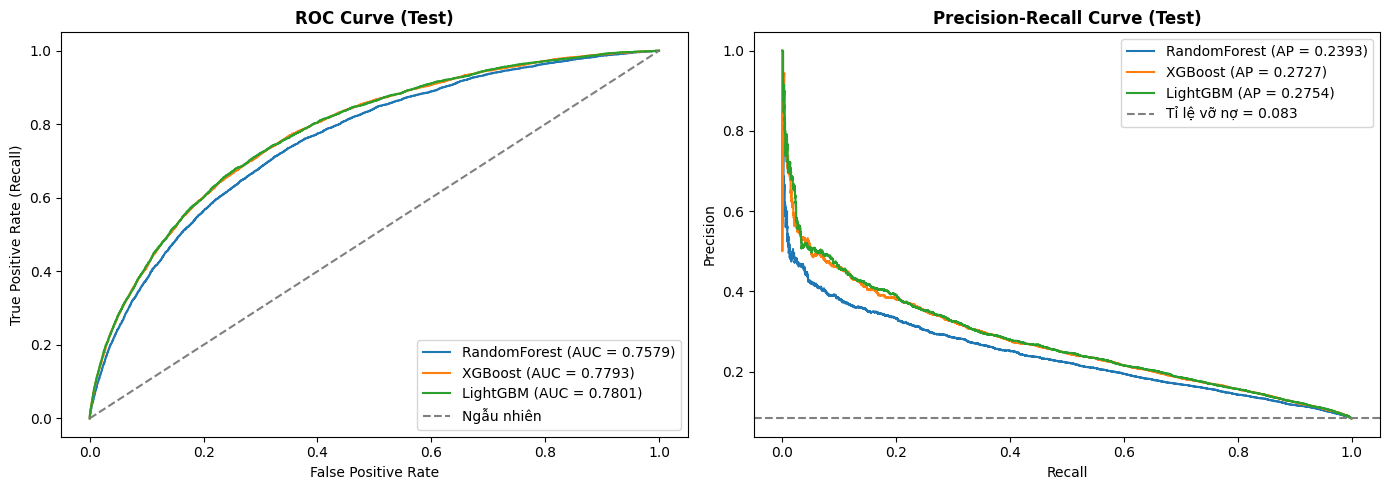

In [40]:
# 6. Đường cong ROC và Precision-Recall trên tập test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, data in results.items():
    false_positive_rates, true_positive_rates, _ = roc_curve(y_test, data['test_probabilities'])
    precisions, recalls, _ = precision_recall_curve(y_test, data['test_probabilities'])
    axes[0].plot(false_positive_rates, true_positive_rates, label=f"{model_name} (AUC = {data['metrics_test']['roc_auc']:.4f})")
    axes[1].plot(recalls, precisions, label=f"{model_name} (AP = {data['metrics_test']['pr_auc']:.4f})")

axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey', label='Ngẫu nhiên')
axes[0].set_title('ROC Curve (Test)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend()

axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label=f'Tỉ lệ vỡ nợ = {y_test.mean():.3f}')
axes[1].set_title('Precision-Recall Curve (Test)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Cải thiện: Stacking Ensemble

Kết hợp xác suất của 3 mô hình bằng Logistic Regression (meta-model):
- Meta-model học trên **xác suất OOF** của tập train (không mô hình nào nhìn thấy dòng mà nó dự đoán) -> tránh rò rỉ
- Khi dự đoán tập test: đưa xác suất của 3 mô hình đã huấn luyện trên toàn bộ tập train vào meta-model

In [41]:
from sklearn.linear_model import LogisticRegression


def to_log_odds(probabilities):
    """Đổi xác suất sang log-odds để meta-model tuyến tính học tốt hơn"""
    clipped = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped))


base_model_names = list(results.keys())
stacking_train_features = np.column_stack([to_log_odds(results[name]['oof_probabilities']) for name in base_model_names])
stacking_test_features = np.column_stack([to_log_odds(results[name]['test_probabilities']) for name in base_model_names])

# 1. Xác suất OOF của chính meta-model (để chọn ngưỡng không bị lạc quan)
meta_model = LogisticRegression(class_weight='balanced', max_iter=1000)
stacking_oof_probabilities = cross_val_predict(meta_model, stacking_train_features, y_train, cv=tuning_cv, method='predict_proba')[:, 1]
stacking_threshold = find_best_f1_threshold(y_train, stacking_oof_probabilities)

# 2. Huấn luyện meta-model trên toàn bộ OOF của tập train, đánh giá trên test
meta_model.fit(stacking_train_features, y_train)
stacking_test_probabilities = meta_model.predict_proba(stacking_test_features)[:, 1]

results['Stacking'] = {
    'threshold': stacking_threshold,
    'metrics_oof': evaluate_predictions(y_train, stacking_oof_probabilities, stacking_threshold),
    'metrics_test': evaluate_predictions(y_test, stacking_test_probabilities, stacking_threshold),
    'oof_probabilities': stacking_oof_probabilities,
    'test_probabilities': stacking_test_probabilities,
}

print("Trọng số meta-model (log-odds):", {name: round(float(weight), 4) for name, weight in zip(base_model_names, meta_model.coef_[0])})
summary_rows = []
for model_name, data in results.items():
    summary_rows.append({
        'Model': model_name,
        'ROC-AUC OOF': data['metrics_oof']['roc_auc'],
        'ROC-AUC Test': data['metrics_test']['roc_auc'],
        'PR-AUC Test': data['metrics_test']['pr_auc'],
        'Precision': data['metrics_test']['precision'],
        'Recall': data['metrics_test']['recall'],
        'F1': data['metrics_test']['f1'],
    })
print(tabulate(pd.DataFrame(summary_rows), headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

Trọng số meta-model (log-odds): {'RandomForest': -0.0666, 'XGBoost': 0.4481, 'LightGBM': 0.5864}
+--------------+---------------+----------------+---------------+-------------+----------+--------+
| Model        |   ROC-AUC OOF |   ROC-AUC Test |   PR-AUC Test |   Precision |   Recall |     F1 |
|--------------+---------------+----------------+---------------+-------------+----------+--------|
| RandomForest |        0.7516 |         0.7579 |        0.2393 |      0.2360 |   0.4507 | 0.3098 |
| XGBoost      |        0.7717 |         0.7793 |        0.2727 |      0.2701 |   0.4236 | 0.3299 |
| LightGBM     |        0.7722 |         0.7801 |        0.2754 |      0.2673 |   0.4453 | 0.3340 |
| Stacking     |        0.7727 |         0.7805 |        0.2753 |      0.2714 |   0.4272 | 0.3319 |
+--------------+---------------+----------------+---------------+-------------+----------+--------+


## 8. Kiểm tra yêu cầu: Precision, Recall, F1 > 0.8 cho cả 2 lớp

1. Với mỗi mô hình, dò ngưỡng trên **OOF của tập train** sao cho chỉ số **nhỏ nhất** trong 6 chỉ số (Precision / Recall / F1 của lớp 0 và lớp 1) là lớn nhất, rồi áp ngưỡng đó lên tập test.
2. Điều kiện cần: với tỉ lệ vỡ nợ p, để Precision lớp 1 ≥ 0.8 và Recall lớp 1 ≥ 0.8 thì số ca báo nhầm FP ≤ 0.25·TP ≤ 0.25·0.8·P
   -> **FPR ≤ 0.2·p / (1 − p)**. Đường ROC của mô hình phải đi qua điểm (FPR tối đa, TPR = 0.8).

In [42]:
from sklearn.metrics import precision_recall_fscore_support


def per_class_metrics(y_true, probabilities, threshold):
    """Precision / Recall / F1 của từng lớp tại một ngưỡng"""
    predictions = (probabilities >= threshold).astype(int)
    precisions, recalls, f1_scores, _ = precision_recall_fscore_support(y_true, predictions, labels=[0, 1], zero_division=0)
    return {
        'precision_0': precisions[0], 'recall_0': recalls[0], 'f1_0': f1_scores[0],
        'precision_1': precisions[1], 'recall_1': recalls[1], 'f1_1': f1_scores[1],
    }


# 1. Dò ngưỡng tối đa hóa chỉ số nhỏ nhất (trên OOF train), đánh giá trên test
requirement_rows = []
for model_name, data in results.items():
    candidate_thresholds = np.unique(np.quantile(data['oof_probabilities'], np.linspace(0.01, 0.99, 197)))
    min_metric_by_threshold = [min(per_class_metrics(y_train, data['oof_probabilities'], threshold).values()) for threshold in candidate_thresholds]
    balanced_threshold = candidate_thresholds[int(np.argmax(min_metric_by_threshold))]

    test_class_metrics = per_class_metrics(y_test, data['test_probabilities'], balanced_threshold)
    requirement_rows.append({'Model': model_name, 'Ngưỡng': balanced_threshold, **test_class_metrics,
                             'Chỉ số nhỏ nhất': min(test_class_metrics.values()),
                             'Đạt > 0.8': all(value > 0.8 for value in test_class_metrics.values())})

print("Chỉ số từng lớp trên tập TEST tại ngưỡng cân bằng tốt nhất:")
print(tabulate(pd.DataFrame(requirement_rows), headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

# 2. Điều kiện cần trên đường ROC
default_rate = y_test.mean()
max_false_positive_rate = 0.2 * default_rate / (1 - default_rate)
print(f"\nTỉ lệ vỡ nợ p = {default_rate:.4f} -> để Precision_1 ≥ 0.8 và Recall_1 ≥ 0.8 cần TPR ≥ 0.8 tại FPR ≤ {max_false_positive_rate:.4f}")

roc_requirement_rows = []
for model_name, data in results.items():
    false_positive_rates, true_positive_rates, _ = roc_curve(y_test, data['test_probabilities'])
    roc_requirement_rows.append({
        'Model': model_name,
        f'TPR thực tế tại FPR = {max_false_positive_rate:.3f}': np.interp(max_false_positive_rate, false_positive_rates, true_positive_rates),
        'FPR thực tế để đạt TPR = 0.8': np.interp(0.8, true_positive_rates, false_positive_rates),
    })
print(tabulate(pd.DataFrame(roc_requirement_rows), headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

Chỉ số từng lớp trên tập TEST tại ngưỡng cân bằng tốt nhất:
+--------------+----------+---------------+------------+--------+---------------+------------+--------+-------------------+-------------+
| Model        |   Ngưỡng |   precision_0 |   recall_0 |   f1_0 |   precision_1 |   recall_1 |   f1_1 |   Chỉ số nhỏ nhất | Đạt > 0.8   |
|--------------+----------+---------------+------------+--------+---------------+------------+--------+-------------------+-------------|
| RandomForest |   0.5527 |        0.9358 |     0.9325 | 0.9341 |        0.2861 |     0.2969 | 0.2914 |            0.2861 | False       |
| XGBoost      |   0.7261 |        0.9382 |     0.9348 | 0.9365 |        0.3115 |     0.3241 | 0.3177 |            0.3115 | False       |
| LightGBM     |   0.7197 |        0.9386 |     0.9325 | 0.9356 |        0.3085 |     0.3305 | 0.3191 |            0.3085 | False       |
| Stacking     |   0.7478 |        0.9385 |     0.9331 | 0.9357 |        0.3085 |     0.3280 | 0.3179 |         

In [43]:
# 3. Bảng đánh đổi ngưỡng của mô hình tốt nhất: muốn bắt được X% ca vỡ nợ thì phải đánh đổi những gì
#    (ngưỡng chọn trên OOF train theo Recall lớp 1 mục tiêu, chỉ số đo trên test)
best_model_name = max(results, key=lambda name: results[name]['metrics_oof']['roc_auc'])
best_oof_probabilities = results[best_model_name]['oof_probabilities']
best_test_probabilities = results[best_model_name]['test_probabilities']
default_oof_probabilities = np.sort(best_oof_probabilities[y_train.to_numpy() == 1])

tradeoff_rows = []
for target_recall in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    # Ngưỡng sao cho target_recall % hồ sơ vỡ nợ (OOF) có xác suất >= ngưỡng
    recall_threshold = default_oof_probabilities[int((1 - target_recall) * len(default_oof_probabilities))]
    test_class_metrics = per_class_metrics(y_test, best_test_probabilities, recall_threshold)
    tradeoff_rows.append({
        'Recall_1 mục tiêu': target_recall,
        'Ngưỡng': recall_threshold,
        'Tỉ lệ hồ sơ bị từ chối': (best_test_probabilities >= recall_threshold).mean(),
        **test_class_metrics,
    })

print(f"Bảng đánh đổi ngưỡng - {best_model_name} (trên tập test):")
print(tabulate(pd.DataFrame(tradeoff_rows), headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

Bảng đánh đổi ngưỡng - Stacking (trên tập test):
+---------------------+----------+--------------------------+---------------+------------+--------+---------------+------------+--------+
|   Recall_1 mục tiêu |   Ngưỡng |   Tỉ lệ hồ sơ bị từ chối |   precision_0 |   recall_0 |   f1_0 |   precision_1 |   recall_1 |   f1_1 |
|---------------------+----------+--------------------------+---------------+------------+--------+---------------+------------+--------|
|              0.3000 |   0.7579 |                   0.0801 |        0.9373 |     0.9407 | 0.9390 |        0.3223 |     0.3094 | 0.3157 |
|              0.4000 |   0.7013 |                   0.1268 |        0.9443 |     0.8997 | 0.9215 |        0.2749 |     0.4177 | 0.3316 |
|              0.5000 |   0.6420 |                   0.1837 |        0.9516 |     0.8476 | 0.8966 |        0.2394 |     0.5269 | 0.3292 |
|              0.6000 |   0.5759 |                   0.2545 |        0.9588 |     0.7799 | 0.8601 |        0.2073 |     0.6

Kết luận mục 8:
- Lớp 0 (không vỡ nợ) đạt > 0.93 ở cả Precision / Recall / F1, nhưng lớp 1 (vỡ nợ) tốt nhất chỉ ~0.31 – 0.33 -> **không đạt** yêu cầu > 0.8 cho cả 2 lớp.
- Điều kiện cần: tại FPR = 1.8%, mô hình tốt nhất chỉ bắt được ~14.5% ca vỡ nợ (cần 80%); muốn bắt 80% ca vỡ nợ phải từ chối nhầm ~39% khách hàng tốt (tối đa cho phép 1.8%).
  Khoảng cách này nằm ở **lượng thông tin trong dữ liệu**, không phải ở thuật toán hay kỹ thuật xử lí lệch nhãn (mục 5: mọi chiến lược cho cùng ROC-AUC).
- Các giải pháp đã thử thêm bằng CV trên tập train nhưng không cải thiện (chênh lệch < 0.0005 ROC-AUC): thêm đặc trưng tỉ lệ / tương tác từ application, huấn luyện chung Cash + Revolving, loại bỏ đặc trưng ít quan trọng. Stacking chỉ tăng +0.0004 ROC-AUC trên test.
- Cách dùng mô hình phù hợp với dữ liệu mất cân bằng: dùng xác suất làm **điểm rủi ro** và chọn ngưỡng theo khẩu vị rủi ro (bảng đánh đổi ở trên).
  Ví dụ: từ chối ~18% hồ sơ rủi ro nhất -> bắt được ~53% ca vỡ nợ, tỉ lệ vỡ nợ của nhóm được duyệt giảm từ 8.35% xuống ~4.8% (= 1 − precision_0).

## 9. Giải thích mô hình bằng SHAP

SHAP value của một đặc trưng = mức đóng góp của đặc trưng đó vào **log-odds vỡ nợ** của từng khách hàng (so với mức trung bình):
- SHAP > 0: đẩy khách hàng về phía **vỡ nợ**, SHAP < 0: đẩy về phía **an toàn**
- Trung bình |SHAP| trên nhiều khách hàng = mức độ mô hình **dựa vào** đặc trưng đó khi ra quyết định

Phân tích trên mô hình đơn tốt nhất (theo ROC-AUC OOF), mẫu ngẫu nhiên 10,000 hồ sơ của tập test.

/home/minora/miniconda3/envs/python3.10/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mô hình được giải thích: LightGBM


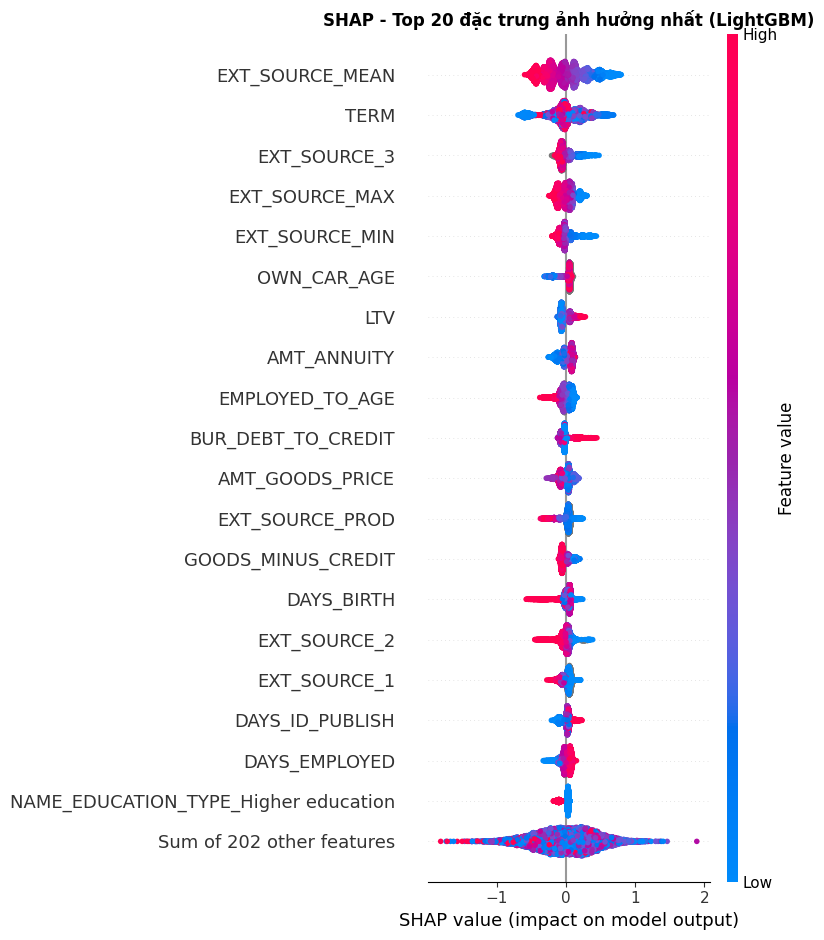

In [44]:
import shap

# 1. Tính SHAP value cho mô hình đơn tốt nhất trên mẫu ngẫu nhiên của tập test
shap_model_name = max(models_and_params, key=lambda name: results[name]['metrics_oof']['roc_auc'])
shap_model = results[shap_model_name]['model']
shap_sample = X_test.sample(n=10000, random_state=42)

# RandomForest nằm trong Pipeline -> giải thích bước model trên dữ liệu đã điền giá trị thiếu
if isinstance(shap_model, Pipeline):
    shap_sample_input = pd.DataFrame(shap_model.named_steps['imputer'].transform(shap_sample), columns=feature_names, index=shap_sample.index)
    shap_model = shap_model.named_steps['model']
else:
    shap_sample_input = shap_sample

shap_explainer = shap.TreeExplainer(shap_model)
shap_values = shap_explainer(shap_sample_input)
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]  # Lấy SHAP của lớp vỡ nợ

# 2. Mức độ ảnh hưởng + chiều tác động của 20 đặc trưng quan trọng nhất
np.random.seed(42)  # SHAP xáo trộn ngẫu nhiên thứ tự vẽ điểm -> cố định seed để biểu đồ giống nhau khi chạy lại
print(f"Mô hình được giải thích: {shap_model_name}")
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.title(f'SHAP - Top 20 đặc trưng ảnh hưởng nhất ({shap_model_name})', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [45]:
# 3. Tổng hợp mức đóng góp theo nguồn dữ liệu
def feature_source(feature_name):
    """Phân loại đặc trưng theo nguồn dữ liệu gốc"""
    if feature_name.startswith('EXT_SOURCE'):
        return 'Điểm tín dụng ngoài (EXT_SOURCE)'
    if feature_name.startswith(('BB_', 'HAS_BB')):
        return 'Bureau balance (lịch sử trả nợ theo tháng)'
    if feature_name.startswith(('BUR_', 'HAS_BUREAU')) or feature_name in ['TOTAL_PTI', 'NEW_LOAN_SHARE']:
        return 'Bureau (khoản vay tại tổ chức khác)'
    return 'Application (hồ sơ vay)'


shap_importance = pd.DataFrame({
    'Đặc trưng': feature_names,
    'Mean |SHAP|': np.abs(shap_values.values).mean(axis=0),
    'SHAP trung bình': shap_values.values.mean(axis=0),
})
shap_importance['Nguồn'] = shap_importance['Đặc trưng'].map(feature_source)
shap_importance = shap_importance.sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)
shap_importance['Tỉ trọng (%)'] = shap_importance['Mean |SHAP|'] / shap_importance['Mean |SHAP|'].sum() * 100

print("Top 20 đặc trưng theo Mean |SHAP|:")
print(tabulate(shap_importance.head(20)[['Đặc trưng', 'Nguồn', 'Mean |SHAP|', 'Tỉ trọng (%)']], headers='keys', tablefmt='psql', floatfmt='.4f'))

source_importance = shap_importance.groupby('Nguồn').agg(
    So_dac_trung=('Đặc trưng', 'size'),
    Ti_trong=('Tỉ trọng (%)', 'sum'),
).sort_values('Ti_trong', ascending=False).rename(columns={'So_dac_trung': 'Số đặc trưng', 'Ti_trong': 'Tỉ trọng đóng góp (%)'})
print("\nĐóng góp theo nguồn dữ liệu:")
print(tabulate(source_importance, headers='keys', tablefmt='psql', floatfmt=('', '.0f', '.2f')))

zero_contribution_features = shap_importance.loc[shap_importance['Mean |SHAP|'] < 1e-4, 'Đặc trưng'].tolist()
print(f"\nSố đặc trưng gần như không được sử dụng (Mean |SHAP| < 1e-4): {len(zero_contribution_features)} / {len(feature_names)}")

Top 20 đặc trưng theo Mean |SHAP|:
+----+--------------------------------------+-------------------------------------+---------------+----------------+
|    | Đặc trưng                            | Nguồn                               |   Mean |SHAP| |   Tỉ trọng (%) |
|----+--------------------------------------+-------------------------------------+---------------+----------------|
|  0 | EXT_SOURCE_MEAN                      | Điểm tín dụng ngoài (EXT_SOURCE)    |        0.2535 |         8.0293 |
|  1 | TERM                                 | Application (hồ sơ vay)             |        0.1811 |         5.7341 |
|  2 | EXT_SOURCE_3                         | Điểm tín dụng ngoài (EXT_SOURCE)    |        0.0865 |         2.7397 |
|  3 | EXT_SOURCE_MAX                       | Điểm tín dụng ngoài (EXT_SOURCE)    |        0.0854 |         2.7037 |
|  4 | EXT_SOURCE_MIN                       | Điểm tín dụng ngoài (EXT_SOURCE)    |        0.0813 |         2.5762 |
|  5 | OWN_CAR_AGE           

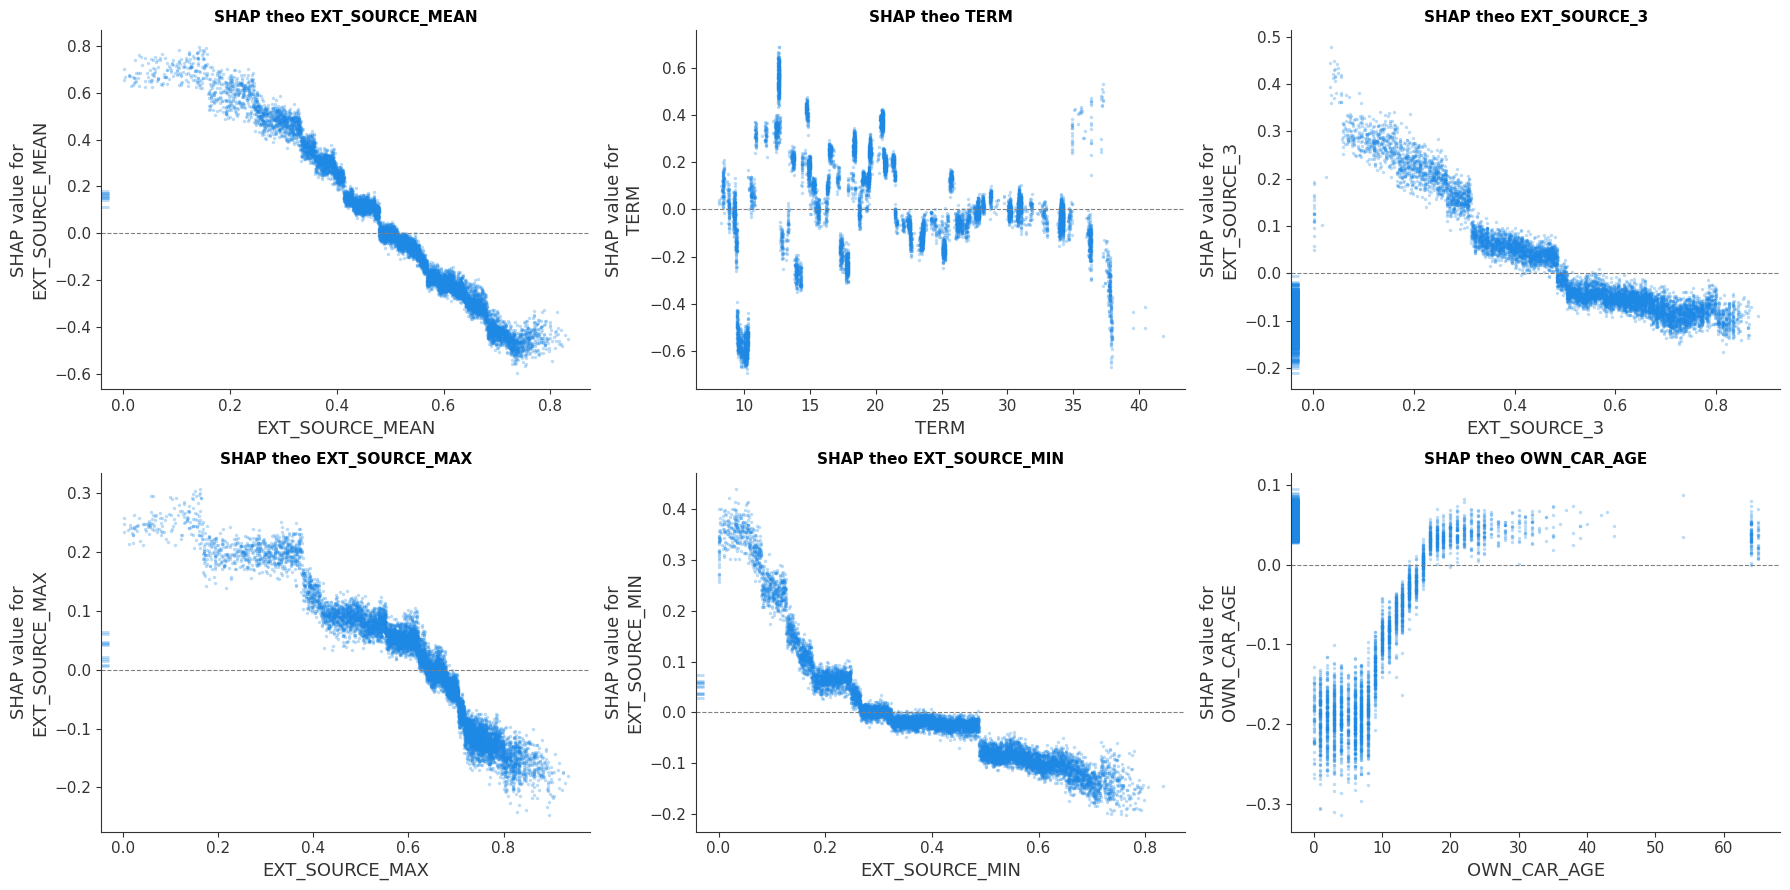

In [46]:
# 4. Dependence plot: giá trị đặc trưng tác động thế nào tới rủi ro (6 đặc trưng quan trọng nhất)
top_shap_features = shap_importance['Đặc trưng'].head(6).tolist()
np.random.seed(42)  # Cố định thứ tự vẽ điểm
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for axis, feature_name in zip(axes.flatten(), top_shap_features):
    shap.dependence_plot(feature_name, shap_values.values, shap_sample_input, interaction_index=None, ax=axis, show=False, alpha=0.3, dot_size=6)
    axis.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    axis.set_title(f'SHAP theo {feature_name}', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

In [47]:
# 5. Mô hình yếu ở nhóm khách hàng nào? (ROC-AUC theo nhóm trên toàn bộ tập test)
shap_test_probabilities = results[shap_model_name]['test_probabilities']
segment_masks = {
    'Toàn bộ tập test': np.ones(len(X_test), dtype=bool),
    'Có lịch sử CIC (HAS_BUREAU = 1)': X_test['HAS_BUREAU'].to_numpy() == 1,
    'Không có lịch sử CIC (HAS_BUREAU = 0)': X_test['HAS_BUREAU'].to_numpy() == 0,
    'Có đủ 3 điểm EXT_SOURCE': X_test[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].notna().all(axis=1).to_numpy(),
    'Thiếu ít nhất 1 điểm EXT_SOURCE': X_test[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].isna().any(axis=1).to_numpy(),
    'Thiếu EXT_SOURCE_3': X_test['EXT_SOURCE_3'].isna().to_numpy(),
}
segment_rows = []
for segment_name, segment_mask in segment_masks.items():
    segment_rows.append({
        'Nhóm khách hàng': segment_name,
        'Số hồ sơ': int(segment_mask.sum()),
        'Tỉ lệ vỡ nợ': y_test.to_numpy()[segment_mask].mean(),
        'ROC-AUC': roc_auc_score(y_test.to_numpy()[segment_mask], shap_test_probabilities[segment_mask]),
    })
print(tabulate(pd.DataFrame(segment_rows), headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

# 6. Vì sao mô hình bỏ sót ca vỡ nợ? So sánh SHAP trung bình: vỡ nợ bị bỏ sót (FN) vs vỡ nợ bắt được (TP)
shap_threshold = results[shap_model_name]['threshold']
sample_is_default = y_test.loc[shap_sample.index].to_numpy() == 1
sample_is_flagged = shap_test_probabilities[X_test.index.get_indexer(shap_sample.index)] >= shap_threshold
missed_default_mask = sample_is_default & ~sample_is_flagged
caught_default_mask = sample_is_default & sample_is_flagged

missed_vs_caught = pd.DataFrame({
    'Đặc trưng': feature_names,
    'SHAP TB - vỡ nợ bắt được (TP)': shap_values.values[caught_default_mask].mean(axis=0),
    'SHAP TB - vỡ nợ bỏ sót (FN)': shap_values.values[missed_default_mask].mean(axis=0),
    'Giá trị TB - TP': shap_sample[caught_default_mask].mean().to_numpy(),
    'Giá trị TB - FN': shap_sample[missed_default_mask].mean().to_numpy(),
})
missed_vs_caught['Chênh lệch SHAP'] = missed_vs_caught['SHAP TB - vỡ nợ bắt được (TP)'] - missed_vs_caught['SHAP TB - vỡ nợ bỏ sót (FN)']
missed_vs_caught = missed_vs_caught.sort_values('Chênh lệch SHAP', ascending=False)

print(f"\nTrong mẫu SHAP: {caught_default_mask.sum()} ca vỡ nợ bắt được (TP), {missed_default_mask.sum()} ca vỡ nợ bị bỏ sót (FN)")
print("Top 10 đặc trưng khiến ca vỡ nợ bị bỏ sót trông 'an toàn' hơn ca bắt được:")
print(tabulate(missed_vs_caught.head(10), headers='keys', tablefmt='psql', showindex=False, floatfmt='.4f'))

+---------------------------------------+------------+---------------+-----------+
| Nhóm khách hàng                       |   Số hồ sơ |   Tỉ lệ vỡ nợ |   ROC-AUC |
|---------------------------------------+------------+---------------+-----------|
| Toàn bộ tập test                      |      55644 |        0.0835 |    0.7801 |
| Có lịch sử CIC (HAS_BUREAU = 1)       |      47760 |        0.0803 |    0.7849 |
| Không có lịch sử CIC (HAS_BUREAU = 0) |       7884 |        0.1029 |    0.7452 |
| Có đủ 3 điểm EXT_SOURCE               |      19662 |        0.0758 |    0.7872 |
| Thiếu ít nhất 1 điểm EXT_SOURCE       |      35982 |        0.0877 |    0.7755 |
| Thiếu EXT_SOURCE_3                    |      10892 |        0.0966 |    0.7556 |
+---------------------------------------+------------+---------------+-----------+

Trong mẫu SHAP: 371 ca vỡ nợ bắt được (TP), 452 ca vỡ nợ bị bỏ sót (FN)
Top 10 đặc trưng khiến ca vỡ nợ bị bỏ sót trông 'an toàn' hơn ca bắt được:
+--------------------+

Kết luận SHAP & hướng cải thiện:
1. **Mô hình dựa nhiều nhất vào điểm tín dụng ngoài (EXT_SOURCE)**: 8 đặc trưng (~4% số đặc trưng) chiếm ~22% tổng đóng góp, EXT_SOURCE_MEAN đứng đầu. Quan hệ đơn điệu, hợp lý: điểm càng thấp -> rủi ro càng cao. Nhóm thiếu EXT_SOURCE_3 có ROC-AUC thấp hơn (0.756).
2. **TERM (AMT_CREDIT / AMT_ANNUITY) đứng thứ 2** với dạng SHAP răng cưa: một số giá trị TERM cụ thể (≈ 10, ≈ 12–13...) cho mức rủi ro rất khác nhau -> TERM đang gián tiếp mã hóa **kỳ hạn + lãi suất của từng gói sản phẩm**, thông tin không có sẵn trong dữ liệu.
3. **Bureau đóng góp ~27%** (BUR_DEBT_TO_CREDIT quan trọng nhất), nhưng **Bureau balance chỉ ~0.3%**: lịch sử quá hạn theo tháng ở tổ chức khác gần như không thêm thông tin sau khi đã có các biến tổng hợp của bureau.
4. **51 / 221 đặc trưng gần như không được dùng** (Mean |SHAP| < 1e-4) -> có thể loại bỏ để mô hình gọn hơn (đã thử bằng CV: ROC-AUC không đổi).
5. **Nhóm yếu nhất: khách hàng không có lịch sử CIC** (14% hồ sơ, tỉ lệ vỡ nợ cao nhất 10.3% nhưng ROC-AUC chỉ 0.745 so với 0.785 ở nhóm có CIC).
6. **Ca vỡ nợ bị bỏ sót (FN) "trông giống khách hàng tốt"**: EXT_SOURCE_MEAN trung bình 0.49 so với 0.29 ở ca bắt được (TP), SHAP của các đặc trưng quan trọng ở nhóm FN đều rất nhỏ.
   Với thông tin hiện có, các hồ sơ này **không phân biệt được** với khách hàng tốt -> không thể sửa bằng thuật toán, chỉ có thể sửa bằng **thông tin mới**.

Hướng cải thiện (theo thứ tự hiệu quả kỳ vọng):
- Bổ sung dữ liệu **hành vi trả nợ** của khách hàng (lịch sử trả góp, thẻ tín dụng, các khoản vay trước) -> giải quyết trực tiếp nhóm FN có hồ sơ tĩnh "đẹp".
- Bổ sung **kỳ hạn và lãi suất thực** của khoản vay để thay cho proxy TERM.
- Khách hàng **không có CIC**: thu thập dữ liệu thay thế (viễn thông, điện nước, xác minh thu nhập) hoặc quy trình thẩm định riêng.
- Vận hành: dùng mô hình như **điểm rủi ro / phân hạng**, chọn ngưỡng theo chi phí (mất vốn khi duyệt nhầm so với lợi nhuận bỏ lỡ khi từ chối nhầm), theo dõi Gini / KS thay vì F1 của lớp thiểu số.

## 10. Kết quả cuối cùng

Đánh giá trên tập test hold-out (55,644 hồ sơ Cash loans, tỉ lệ vỡ nợ thật 8.35%), ngưỡng quyết định tối ưu F1 chọn từ OOF của tập train:

| Model | ROC-AUC | Gini | KS | PR-AUC | Accuracy | Precision lớp 1 | Recall lớp 1 | F1 lớp 1 |
|---|---|---|---|---|---|---|---|---|
| Pipeline ban đầu (trước khi sửa) | 0.7560 (OOF) | – | – | – | 0.7051 | 0.1732 | 0.6700 | 0.2753 |
| RandomForest | 0.7579 | 0.5158 | 0.3873 | 0.2393 | 0.8324 | 0.2360 | 0.4507 | 0.3098 |
| XGBoost | 0.7793 | 0.5585 | 0.4197 | 0.2727 | 0.8564 | 0.2701 | 0.4236 | 0.3299 |
| **LightGBM** | **0.7801** | **0.5602** | **0.4234** | **0.2754** | 0.8518 | 0.2673 | 0.4453 | **0.3340** |
| Stacking (RF + XGB + LGBM) | 0.7805 | 0.5610 | – | 0.2753 | – | 0.2714 | 0.4272 | 0.3319 |

Chi tiết mô hình đề xuất **LightGBM** (`num_leaves = 24`, `min_child_samples = 400`, ngưỡng = 0.6582):

| Lớp | Precision | Recall | F1 | Số hồ sơ |
|---|---|---|---|---|
| 0 - Không vỡ nợ | 0.9462 | 0.8888 | 0.9166 | 51,000 |
| 1 - Vỡ nợ | 0.2673 | 0.4453 | 0.3340 | 4,644 |

Confusion matrix: TN = 45,330 · FP = 5,670 · FN = 2,576 · TP = 2,068

Đánh giá yêu cầu **Precision / Recall / F1 > 0.8 cho cả 2 lớp: KHÔNG ĐẠT** với dữ liệu hiện có (application + bureau + bureau_balance).
- Lớp 0 đạt > 0.88 ở cả 3 chỉ số; lớp 1 tốt nhất ~0.31 – 0.33 (mục 8).
- Điều kiện cần là TPR ≥ 0.8 tại FPR ≤ 1.8%, mô hình chỉ đạt TPR ≈ 0.145 -> giới hạn nằm ở lượng thông tin trong dữ liệu (mục 9), không phải ở thuật toán hay cách xử lí lệch nhãn (mục 5).

Mô hình triển khai: **LightGBM** — `mlops_artifacts/LightGBM/model.onnx` + ngưỡng / danh sách 221 đặc trưng trong `metadata.json`. Stacking chỉ hơn +0.0004 ROC-AUC nhưng cần chạy cả 3 mô hình nên không chọn.